# Transcript Analysis Helper

Interactively explore the transcript `.txt` files housed under `data/` using the helpers defined in `script.py`.


In [103]:
# Set random seeds for reproducibility across the entire experiment
RANDOM_SEED = 42

import random
import numpy as np

# Set seeds for Python's random module
random.seed(RANDOM_SEED)

# Set seed for NumPy
np.random.seed(RANDOM_SEED)

# Set seed for scikit-learn (if available)
try:
    from sklearn.utils import check_random_state
    sklearn_random_state = check_random_state(RANDOM_SEED)
except ImportError:
    pass

print(f"Random seed set to: {RANDOM_SEED}")
print("This ensures reproducibility of all random operations in this notebook.")


Random seed set to: 42
This ensures reproducibility of all random operations in this notebook.


In [104]:
from pathlib import Path

import pandas as pd

from dataloader import TranscriptLoader

loader = TranscriptLoader()
print(f"Data directory: {loader.data_dir}")


Data directory: /Users/bentindal/Desktop/CognoSpeak/data


In [105]:
from file_validator import validate_file_naming, print_validation_report

# Check for files that don't follow naming convention
naming_issues = validate_file_naming(Path(loader.data_dir))
print_validation_report(naming_issues)


FILE NAMING CONVENTION CHECK

Accepted formats:
  - Process-XXX__PFT.txt or Process-XXX__SFT.txt (double underscore)
  - Process-XXX_PFT.txt or Process-XXX_SFT.txt (single underscore)
Files should be in directories: Process-rec-XXX/ or Process-test-XXX/

✅ All files follow the naming convention!


In [106]:
transcript_paths = loader.discover_transcript_files()
len(transcript_paths), transcript_paths[:5]


(179,
 [PosixPath('/Users/bentindal/Desktop/CognoSpeak/data/Process-rec-004/Process-rec-004__PFT.txt'),
  PosixPath('/Users/bentindal/Desktop/CognoSpeak/data/Process-rec-004/Process-rec-004__SFT.txt'),
  PosixPath('/Users/bentindal/Desktop/CognoSpeak/data/Process-rec-006/Process-rec-006_PFT.txt'),
  PosixPath('/Users/bentindal/Desktop/CognoSpeak/data/Process-rec-006/Process-rec-006_SFT.txt'),
  PosixPath('/Users/bentindal/Desktop/CognoSpeak/data/Process-rec-009/Process-rec-009__PFT.txt')])

In [107]:
example_path = transcript_paths[0]
example_df = loader.load_transcript(example_path)
example_df.head()


,start_time,end_time,token,recording,task,recording_number,source_path
0,0.445333,0.445333,plank,Process-rec-004,PFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...
1,2.099429,2.099429,pool,Process-rec-004,PFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...
2,4.835048,4.835048,pool,Process-rec-004,PFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...
3,8.270476,8.270476,plethora,Process-rec-004,PFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...
4,9.924571,9.924571,puzzle,Process-rec-004,PFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...


In [108]:
frames = loader.load_all_transcripts(transcript_paths)
combined = loader.concatenate_transcripts(frames.values())
summary = loader.summarize_structure(combined)
summary.to_frame(name='value')


,value
rows,3241
recordings,89
tasks,"PFT, SFT"
start_time_range,"(0.0, 62.605016)"
end_time_range,"(0.0, 62.690496)"
missing_values,0


In [109]:
metadata = loader.load_metadata()
metadata.head()


,recording,age,gender,diagnosis,MMSE,annotator,notes,recording_number
0,Process-rec-143,70.0,male,DEMENTIA,24.0,Madhu,"SFT: all good, something said at the end, can'...",143
1,Process-rec-091,73.0,female,DEMENTIA,20.0,Kevin,"SFT: good, repeated a couple words towards the...",91
2,Process-test-038,73.0,male,DEMENTIA,<NA>,Kevin,"SFT: good until end, noticeable pauses; PFT: n...",38
3,Process-rec-107,75.0,female,DEMENTIA,<NA>,Kevin,"SFT: good, noticeable pauses, repeated word; P...",107
4,Process-rec-040,77.0,male,DEMENTIA,<NA>,Kevin,"SFT: all good; PFT: poor, apologised for strug...",40


In [110]:
# Data Summary: Count by Diagnosis and Task (PFT/SFT)
import re

# Determine the correct column name for recordings in metadata
if 'anyon_IDs' in metadata.columns:
    recording_col = 'anyon_IDs'
elif 'recording' in metadata.columns:
    recording_col = 'recording'
else:
    print("Available columns in metadata:", metadata.columns.tolist())
    raise ValueError("Could not find recording column in metadata. Expected 'anyon_IDs' or 'recording'")

# Get all transcript files
transcript_paths = loader.discover_transcript_files()

# Extract recording name and task from each transcript file
transcript_data = []
for path in transcript_paths:
    recording_name = path.parent.name
    task = loader.infer_task_from_filename(path.name)
    if task in ['PFT', 'SFT']:  # Only count PFT and SFT
        transcript_data.append({
            'recording': recording_name,
            'task': task,
            'filename': path.name
        })

transcript_df = pd.DataFrame(transcript_data)

# Merge with metadata to get diagnosis
# Rename the recording column if needed
metadata_for_merge = metadata.copy()
if recording_col != 'recording':
    metadata_for_merge = metadata_for_merge.rename(columns={recording_col: 'recording'})

transcript_with_diag = transcript_df.merge(
    metadata_for_merge[['recording', 'diagnosis']],
    on='recording',
    how='left'
)

# Filter to only records with diagnosis
transcript_with_diag = transcript_with_diag.dropna(subset=['diagnosis'])

# Create summary tables
print("=" * 80)
print("DATA SUMMARY: Transcript Files by Diagnosis and Task")
print("=" * 80)

# Total count
print(f"\nTotal transcript files: {len(transcript_with_diag)}")
print(f"Total unique recordings: {transcript_with_diag['recording'].nunique()}")

# Count by diagnosis
print("\n" + "-" * 80)
print("Count by Diagnosis:")
print("-" * 80)
diag_counts = transcript_with_diag['diagnosis'].value_counts().sort_index()
for diag, count in diag_counts.items():
    print(f"  {diag:12s}: {count:3d} files")

# Count by task
print("\n" + "-" * 80)
print("Count by Task:")
print("-" * 80)
task_counts = transcript_with_diag['task'].value_counts().sort_index()
for task, count in task_counts.items():
    print(f"  {task:12s}: {count:3d} files")

# Cross-tabulation: Diagnosis × Task
print("\n" + "-" * 80)
print("Cross-tabulation: Diagnosis × Task")
print("-" * 80)
crosstab = pd.crosstab(transcript_with_diag['diagnosis'], transcript_with_diag['task'], margins=True)
print(crosstab.to_string())

# Count unique recordings by diagnosis and task
print("\n" + "-" * 80)
print("Unique Recordings by Diagnosis × Task")
print("-" * 80)
recording_crosstab = transcript_with_diag.groupby(['diagnosis', 'task'])['recording'].nunique().unstack(fill_value=0)
recording_crosstab['Total'] = recording_crosstab.sum(axis=1)
recording_crosstab.loc['Total'] = recording_crosstab.sum(axis=0)
print(recording_crosstab.to_string())

print("\n" + "=" * 80)


DATA SUMMARY: Transcript Files by Diagnosis and Task

Total transcript files: 179
Total unique recordings: 89

--------------------------------------------------------------------------------
Count by Diagnosis:
--------------------------------------------------------------------------------
  DEMENTIA    :  40 files
  HC          :  78 files
  MCI         :  61 files

--------------------------------------------------------------------------------
Count by Task:
--------------------------------------------------------------------------------
  PFT         :  90 files
  SFT         :  89 files

--------------------------------------------------------------------------------
Cross-tabulation: Diagnosis × Task
--------------------------------------------------------------------------------
task       PFT  SFT  All
diagnosis               
DEMENTIA    20   20   40
HC          39   39   78
MCI         31   30   61
All         90   89  179

--------------------------------------------------

In [111]:
# Diagnostic: Identify Missing PFT/SFT Files
print("=" * 80)
print("DIAGNOSTIC: Missing PFT/SFT Files by Recording")
print("=" * 80)

# Determine the correct column name for recordings in metadata
# Check common column names
if 'anyon_IDs' in metadata.columns:
    recording_col = 'anyon_IDs'
elif 'recording' in metadata.columns:
    recording_col = 'recording'
else:
    print("Available columns in metadata:", metadata.columns.tolist())
    raise ValueError("Could not find recording column in metadata. Expected 'anyon_IDs' or 'recording'")

# Get all recordings from metadata
all_recordings = set(metadata[recording_col].dropna().unique())

# Get all recordings that have transcript files
recordings_with_files = set(transcript_df['recording'].unique())

# Group transcript files by recording and task
recording_tasks = transcript_df.groupby('recording')['task'].apply(set).to_dict()

# Analyze each recording
missing_pft = []
missing_sft = []
missing_both = []
has_both = []
only_pft = []
only_sft = []
no_transcripts = []

for recording in sorted(all_recordings):
    if recording not in recordings_with_files:
        no_transcripts.append(recording)
        continue
    
    tasks = recording_tasks.get(recording, set())
    has_pft = 'PFT' in tasks
    has_sft = 'SFT' in tasks
    
    if has_pft and has_sft:
        has_both.append(recording)
    elif has_pft and not has_sft:
        only_pft.append(recording)
        missing_sft.append(recording)
    elif has_sft and not has_pft:
        only_sft.append(recording)
        missing_pft.append(recording)
    else:
        missing_both.append(recording)

# Print summary
print(f"\nTotal recordings in metadata: {len(all_recordings)}")
print(f"Recordings with transcript files: {len(recordings_with_files)}")
print(f"Recordings with BOTH PFT and SFT: {len(has_both)}")
print(f"Recordings with ONLY PFT (missing SFT): {len(only_pft)}")
print(f"Recordings with ONLY SFT (missing PFT): {len(only_sft)}")
print(f"Recordings with NEITHER: {len(missing_both)}")
print(f"Recordings in metadata but NO transcript files: {len(no_transcripts)}")

# Detailed lists
if missing_sft:
    print("\n" + "-" * 80)
    print(f"Recordings MISSING SFT files ({len(missing_sft)}):")
    print("-" * 80)
    for rec in sorted(missing_sft):
        diag = metadata[metadata[recording_col] == rec]['diagnosis'].values
        diag_str = diag[0] if len(diag) > 0 else 'UNKNOWN'
        print(f"  {rec:25s} (diagnosis: {diag_str})")

if missing_pft:
    print("\n" + "-" * 80)
    print(f"Recordings MISSING PFT files ({len(missing_pft)}):")
    print("-" * 80)
    for rec in sorted(missing_pft):
        diag = metadata[metadata[recording_col] == rec]['diagnosis'].values
        diag_str = diag[0] if len(diag) > 0 else 'UNKNOWN'
        print(f"  {rec:25s} (diagnosis: {diag_str})")

if missing_both:
    print("\n" + "-" * 80)
    print(f"Recordings MISSING BOTH PFT and SFT files ({len(missing_both)}):")
    print("-" * 80)
    for rec in sorted(missing_both):
        diag = metadata[metadata[recording_col] == rec]['diagnosis'].values
        diag_str = diag[0] if len(diag) > 0 else 'UNKNOWN'
        print(f"  {rec:25s} (diagnosis: {diag_str})")

if no_transcripts:
    print("\n" + "-" * 80)
    print(f"Recordings in metadata but NO transcript files found ({len(no_transcripts)}):")
    print("-" * 80)
    for rec in sorted(no_transcripts):
        diag = metadata[metadata[recording_col] == rec]['diagnosis'].values
        diag_str = diag[0] if len(diag) > 0 else 'UNKNOWN'
        print(f"  {rec:25s} (diagnosis: {diag_str})")

# Check for recordings with transcript files but not in metadata
recordings_not_in_metadata = recordings_with_files - all_recordings
if recordings_not_in_metadata:
    print("\n" + "-" * 80)
    print(f"Recordings with transcript files but NOT in metadata ({len(recordings_not_in_metadata)}):")
    print("-" * 80)
    for rec in sorted(recordings_not_in_metadata):
        tasks = recording_tasks.get(rec, set())
        tasks_str = ', '.join(sorted(tasks))
        print(f"  {rec:25s} (tasks: {tasks_str})")

# Expected vs Actual
print("\n" + "=" * 80)
print("EXPECTED vs ACTUAL COUNTS")
print("=" * 80)
print(f"Expected: 90 PFT files, 90 SFT files")
print(f"Actual PFT files: {len(transcript_df[transcript_df['task'] == 'PFT'])}")
print(f"Actual SFT files: {len(transcript_df[transcript_df['task'] == 'SFT'])}")
print(f"Missing PFT files: {90 - len(transcript_df[transcript_df['task'] == 'PFT'])}")
print(f"Missing SFT files: {90 - len(transcript_df[transcript_df['task'] == 'SFT'])}")
print("=" * 80)


DIAGNOSTIC: Missing PFT/SFT Files by Recording

Total recordings in metadata: 90
Recordings with transcript files: 89
Recordings with BOTH PFT and SFT: 89
Recordings with ONLY PFT (missing SFT): 0
Recordings with ONLY SFT (missing PFT): 0
Recordings with NEITHER: 0
Recordings in metadata but NO transcript files: 1

--------------------------------------------------------------------------------
Recordings in metadata but NO transcript files found (1):
--------------------------------------------------------------------------------
  Process-test-014          (diagnosis: HC)

EXPECTED vs ACTUAL COUNTS
Expected: 90 PFT files, 90 SFT files
Actual PFT files: 90
Actual SFT files: 89
Missing PFT files: 0
Missing SFT files: 1


In [112]:
# Check actual file system for missing files
print("=" * 80)
print("FILE SYSTEM CHECK: Looking for PFT/SFT files in data directory")
print("=" * 80)

# Determine the correct column name for recordings in metadata (same as previous cell)
if 'anyon_IDs' in metadata.columns:
    recording_col = 'anyon_IDs'
elif 'recording' in metadata.columns:
    recording_col = 'recording'
else:
    print("Available columns in metadata:", metadata.columns.tolist())
    raise ValueError("Could not find recording column in metadata. Expected 'anyon_IDs' or 'recording'")

# Get all recordings from metadata (if not already defined)
if 'all_recordings' not in locals():
    all_recordings = set(metadata[recording_col].dropna().unique())

# Check each recording folder for actual files
file_system_check = []
for recording in sorted(all_recordings):
    recording_dir = loader.data_dir / recording
    if not recording_dir.exists():
        file_system_check.append({
            'recording': recording,
            'folder_exists': False,
            'pft_files': [],
            'sft_files': [],
            'other_files': []
        })
        continue
    
    # Look for all .txt files in this directory
    txt_files = list(recording_dir.glob('*.txt'))
    pft_files = []
    sft_files = []
    other_files = []
    
    for txt_file in txt_files:
        task = loader.infer_task_from_filename(txt_file.name)
        if task == 'PFT':
            pft_files.append(txt_file.name)
        elif task == 'SFT':
            sft_files.append(txt_file.name)
        else:
            other_files.append(txt_file.name)
    
    file_system_check.append({
        'recording': recording,
        'folder_exists': True,
        'pft_files': pft_files,
        'sft_files': sft_files,
        'other_files': other_files
    })

# Find recordings with files in folder but not detected
print("\nRecordings with files in folder but not properly detected:")
print("-" * 80)
issues_found = False
for check in file_system_check:
    rec = check['recording']
    has_pft_in_folder = len(check['pft_files']) > 0
    has_sft_in_folder = len(check['sft_files']) > 0
    
    # Check if this recording was in our transcript_df
    in_transcript_df = rec in transcript_df['recording'].values
    if in_transcript_df:
        tasks_in_df = set(transcript_df[transcript_df['recording'] == rec]['task'].values)
    else:
        tasks_in_df = set()
    
    has_pft_in_df = 'PFT' in tasks_in_df
    has_sft_in_df = 'SFT' in tasks_in_df
    
    # Report discrepancies
    if check['folder_exists']:
        if has_pft_in_folder and not has_pft_in_df:
            print(f"  {rec:25s} - PFT file exists in folder but not detected: {check['pft_files']}")
            issues_found = True
        if has_sft_in_folder and not has_sft_in_df:
            print(f"  {rec:25s} - SFT file exists in folder but not detected: {check['sft_files']}")
            issues_found = True
        if not has_pft_in_folder and has_pft_in_df:
            print(f"  {rec:25s} - PFT detected but file not found in folder")
            issues_found = True
        if not has_sft_in_folder and has_sft_in_df:
            print(f"  {rec:25s} - SFT detected but file not found in folder")
            issues_found = True

if not issues_found:
    print("  No discrepancies found between file system and detected files.")

# Show recordings with missing files
print("\n" + "-" * 80)
print("Recordings with missing PFT or SFT files (from file system check):")
print("-" * 80)
missing_from_filesystem = []
for check in file_system_check:
    rec = check['recording']
    has_pft = len(check['pft_files']) > 0
    has_sft = len(check['sft_files']) > 0
    
    if not has_pft or not has_sft:
        diag = metadata[metadata[recording_col] == rec]['diagnosis'].values
        diag_str = diag[0] if len(diag) > 0 else 'UNKNOWN'
        status = []
        if not has_pft:
            status.append("MISSING PFT")
        if not has_sft:
            status.append("MISSING SFT")
        if not check['folder_exists']:
            status.append("FOLDER NOT FOUND")
        
        missing_from_filesystem.append({
            'recording': rec,
            'diagnosis': diag_str,
            'status': ', '.join(status),
            'pft_files': check['pft_files'],
            'sft_files': check['sft_files']
        })

if missing_from_filesystem:
    for item in sorted(missing_from_filesystem, key=lambda x: x['recording']):
        print(f"  {item['recording']:25s} ({item['diagnosis']:10s}) - {item['status']}")
        if item['pft_files']:
            print(f"    Found PFT files: {', '.join(item['pft_files'])}")
        if item['sft_files']:
            print(f"    Found SFT files: {', '.join(item['sft_files'])}")
else:
    print("  All recordings have both PFT and SFT files in their folders.")

print("\n" + "=" * 80)


FILE SYSTEM CHECK: Looking for PFT/SFT files in data directory

Recordings with files in folder but not properly detected:
--------------------------------------------------------------------------------
  No discrepancies found between file system and detected files.

--------------------------------------------------------------------------------
Recordings with missing PFT or SFT files (from file system check):
--------------------------------------------------------------------------------
  Process-test-014          (HC        ) - MISSING PFT, MISSING SFT



In [113]:
merged = loader.merge_with_metadata(combined, metadata)
merged[['recording', 'diagnosis']].drop_duplicates().head()


,recording,diagnosis
0,Process-rec-004,MCI
41,Process-rec-006,DEMENTIA
69,Process-rec-009,HC
116,Process-rec-010,HC
159,Process-rec-013,MCI


In [114]:
# Optional: persist the combined dataset for downstream work
output_path = Path('combined_transcripts.parquet')
combined.to_parquet(output_path, index=False)
output_path


PosixPath('combined_transcripts.parquet')

In [115]:
from pathlib import Path
from pause_analyzer import analyze_pauses

# Generate pause_summary.csv if it doesn't exist
pause_summary_path = Path('pause_summary.csv')
if not pause_summary_path.exists():
    print("Generating pause_summary.csv...")
    analyze_pauses(Path(loader.data_dir), pause_summary_path)
    print(f"✓ Created {pause_summary_path}")
else:
    print(f"✓ {pause_summary_path} already exists")


✓ pause_summary.csv already exists


## Pause Metrics by Diagnosis

Merge the pause statistics from `pause_summary.csv` with the subject metadata to compare cohorts (Dementia, MCI, HC).


In [116]:
import matplotlib.pyplot as plt
import seaborn as sns

pause_summary = pd.read_csv('pause_summary.csv')
pause_summary['recording'] = pause_summary['transcript'].str.split('/').str[0]

pause_with_diag = pause_summary.merge(
    metadata.rename(columns={'anyon_IDs': 'recording'})[['recording', 'diagnosis']],
    on='recording',
    how='left'
)
pause_with_diag.dropna(subset=['diagnosis'], inplace=True)
pause_with_diag.head()


,transcript,token_count,pause_count,pause_mean,pause_median,pause_min,pause_max,pause_std,pause_total,pause_q1,pause_q2,pause_q3,recording,diagnosis
0,Process-rec-004/Process-rec-004__PFT.txt,23,22,2.478251,1.972190,1.208762,7.697905,1.607948,54.521524,1.383714,1.972190,2.815143,Process-rec-004,MCI
1,Process-rec-004/Process-rec-004__SFT.txt,18,17,3.125438,2.160889,0.762667,13.028889,3.040823,53.132445,1.398222,2.160889,3.686222,Process-rec-004,MCI
2,Process-rec-006/Process-rec-006_PFT.txt,18,17,2.535626,1.223342,0.190297,13.555324,3.487955,43.105637,0.581923,1.223342,2.779910,Process-rec-006,DEMENTIA
3,Process-rec-006/Process-rec-006_SFT.txt,10,9,2.439959,1.364377,0.278641,8.438261,2.835415,21.959633,0.387204,1.364377,4.278873,Process-rec-006,DEMENTIA
4,Process-rec-009/Process-rec-009__PFT.txt,26,25,1.384587,1.034487,0.188424,5.889187,1.277464,34.614670,0.500618,1.034487,1.814047,Process-rec-009,HC


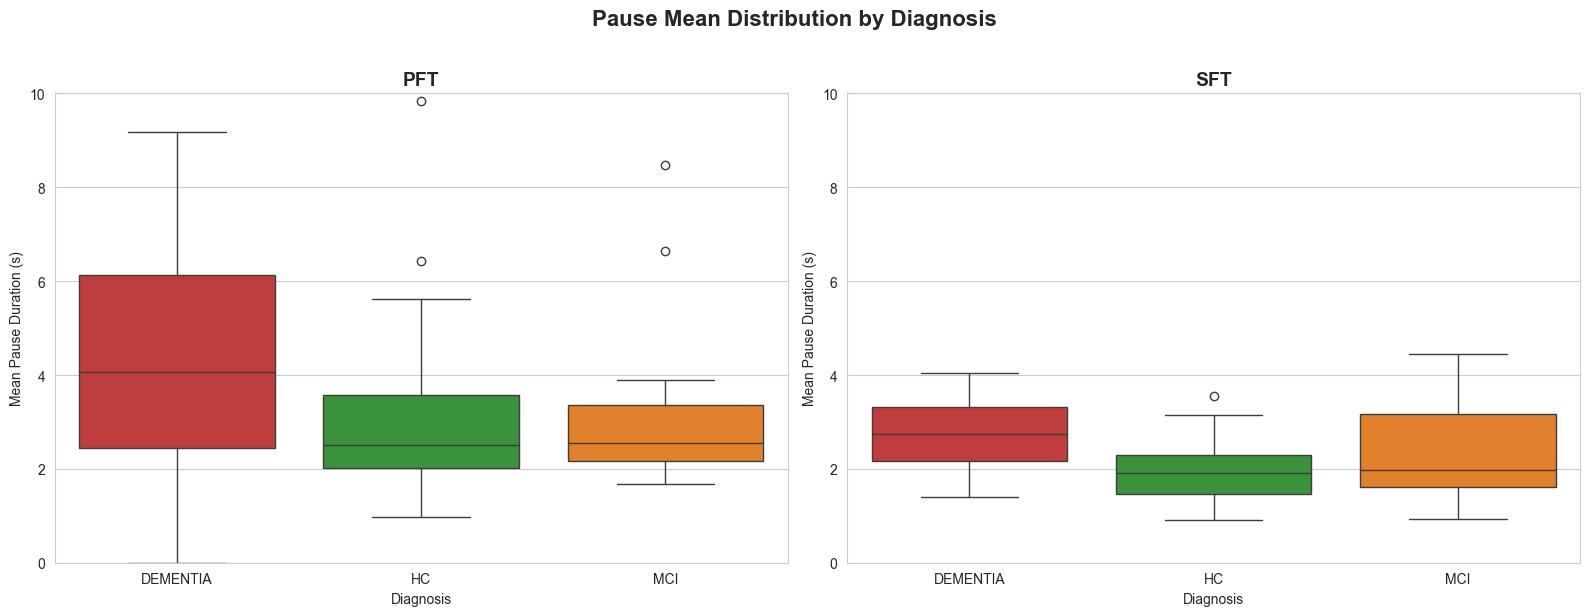


diagnosis Statistics:
           count      mean       std       25%       50%       75%
diagnosis                                                         
DEMENTIA    20.0  4.403681  2.764860  2.450600  4.073312  6.130733
HC          39.0  3.057931  1.658557  2.024173  2.498866  3.567146
MCI         31.0  4.197133  7.086618  2.169523  2.555044  3.368917

diagnosis Statistics:
           count      mean       std       25%       50%       75%
diagnosis                                                         
DEMENTIA    20.0  2.773115  0.794132  2.167873  2.751766  3.315327
HC          39.0  1.902879  0.656572  1.459291  1.902099  2.292626
MCI         30.0  2.308267  1.034430  1.616069  1.983833  3.160348


In [117]:
import re
from plotting import plot_3class_comparison, print_descriptive_stats

# Convert diagnosis to categorical with desired order
pause_with_diag['diagnosis'] = pd.Categorical(
    pause_with_diag['diagnosis'],
    categories=['DEMENTIA', 'HC', 'MCI'],
    ordered=True
)

# Extract task (PFT/SFT) from transcript path
pause_with_diag['task'] = pause_with_diag['transcript'].str.extract(r'([PS]FT)', flags=re.IGNORECASE)[0].str.upper()

# Filter to only PFT and SFT tasks
pause_with_diag_filtered = pause_with_diag[pause_with_diag['task'].isin(['PFT', 'SFT'])].copy()

# Prepare data
pft_data = pause_with_diag_filtered[pause_with_diag_filtered['task'] == 'PFT']
sft_data = pause_with_diag_filtered[pause_with_diag_filtered['task'] == 'SFT']

# Plot comparison
plot_3class_comparison(pft_data, sft_data)

# Print descriptive statistics
print_descriptive_stats(pft_data, 'diagnosis')
print_descriptive_stats(sft_data, 'diagnosis')


## Statistical Tests: 3-Class Comparison

Two-tailed independent samples t-tests to compare means between diagnosis groups.


TWO-TAILED T-TESTS: PFT

DEMENTIA vs HC:
  t-statistic: 2.3375
  p-value: 0.0229
  Significant (p < 0.05): Yes *

DEMENTIA vs MCI:
  t-statistic: 0.1240
  p-value: 0.9018
  Significant (p < 0.05): No 

MCI vs HC:
  t-statistic: 0.9726
  p-value: 0.3342
  Significant (p < 0.05): No 
TWO-TAILED T-TESTS: SFT

DEMENTIA vs HC:
  t-statistic: 4.4855
  p-value: 0.0000
  Significant (p < 0.05): Yes *

DEMENTIA vs MCI:
  t-statistic: 1.7011
  p-value: 0.0954
  Significant (p < 0.05): No 

MCI vs HC:
  t-statistic: 1.9844
  p-value: 0.0513
  Significant (p < 0.05): No 


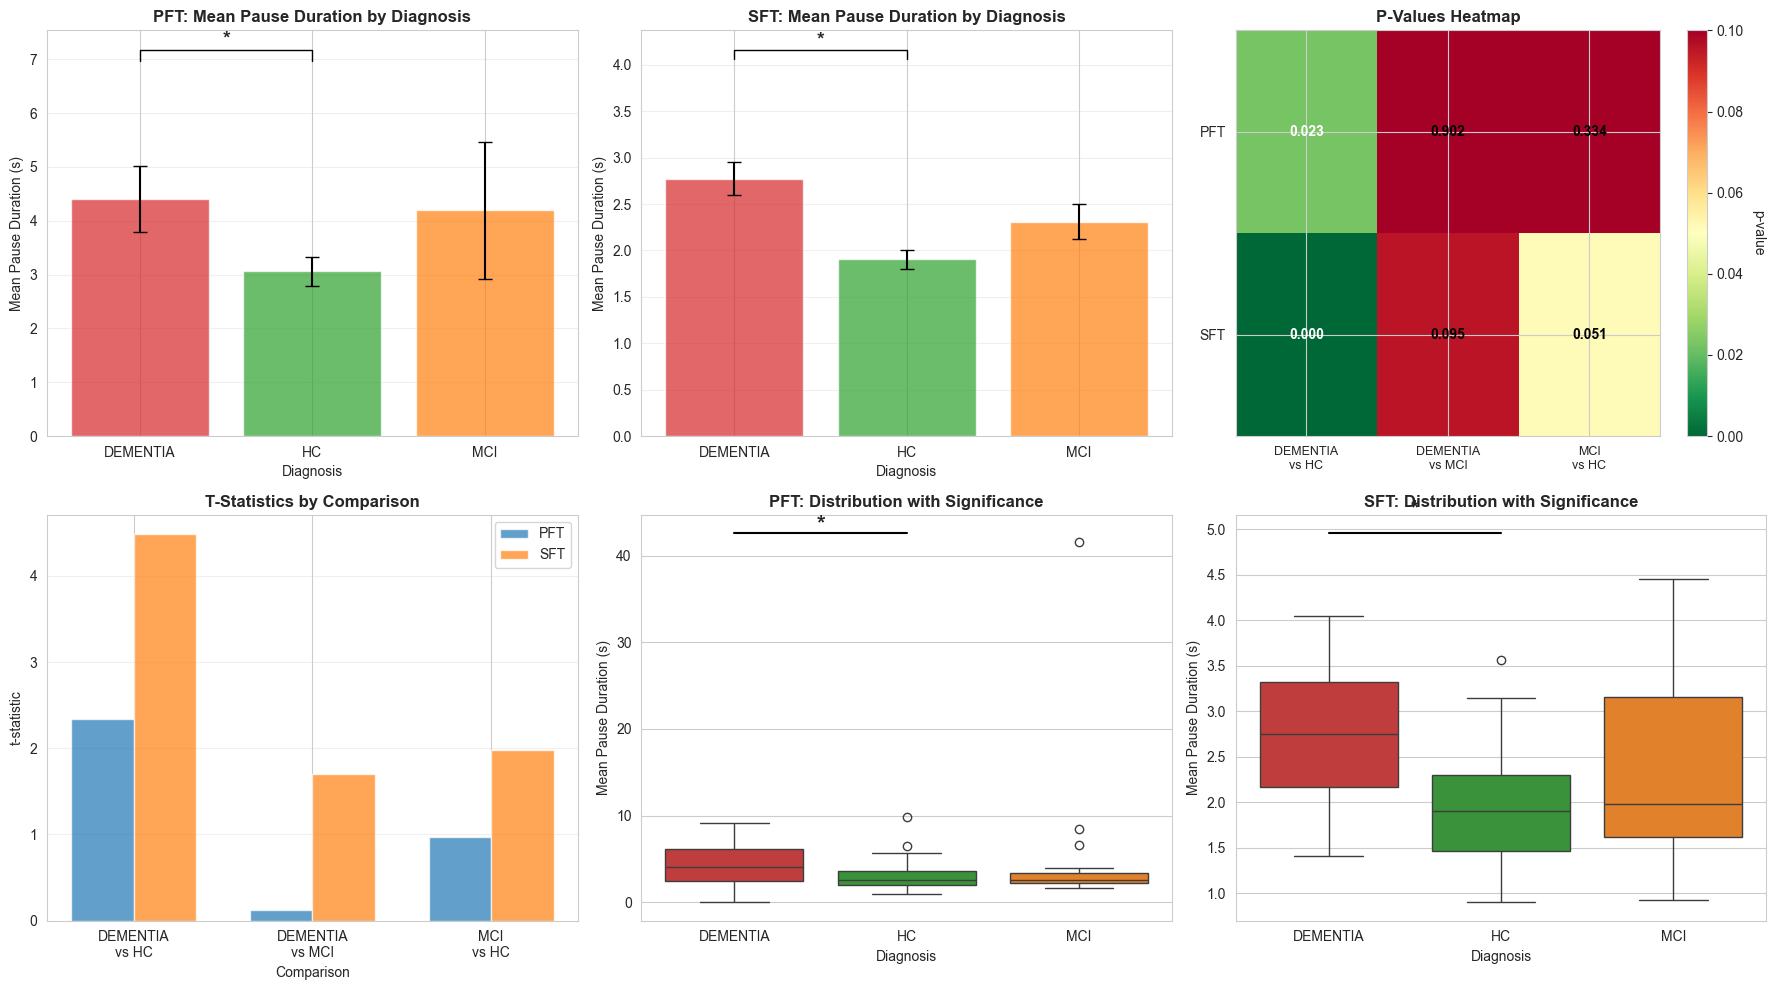


SUMMARY: Significant differences (p < 0.05) are marked with *


In [118]:
from statistical_tests import perform_3class_ttests, print_ttest_results, plot_3class_statistics

# Perform t-tests
test_results = perform_3class_ttests(pft_data, sft_data)

# Print results
print_ttest_results(test_results)

# Create visualizations
plot_3class_statistics(pft_data, sft_data, test_results)


## Healthy vs Non-Healthy by Task (PFT and SFT)

Compare Healthy vs Non-Healthy groups separately for PFT and SFT tasks.


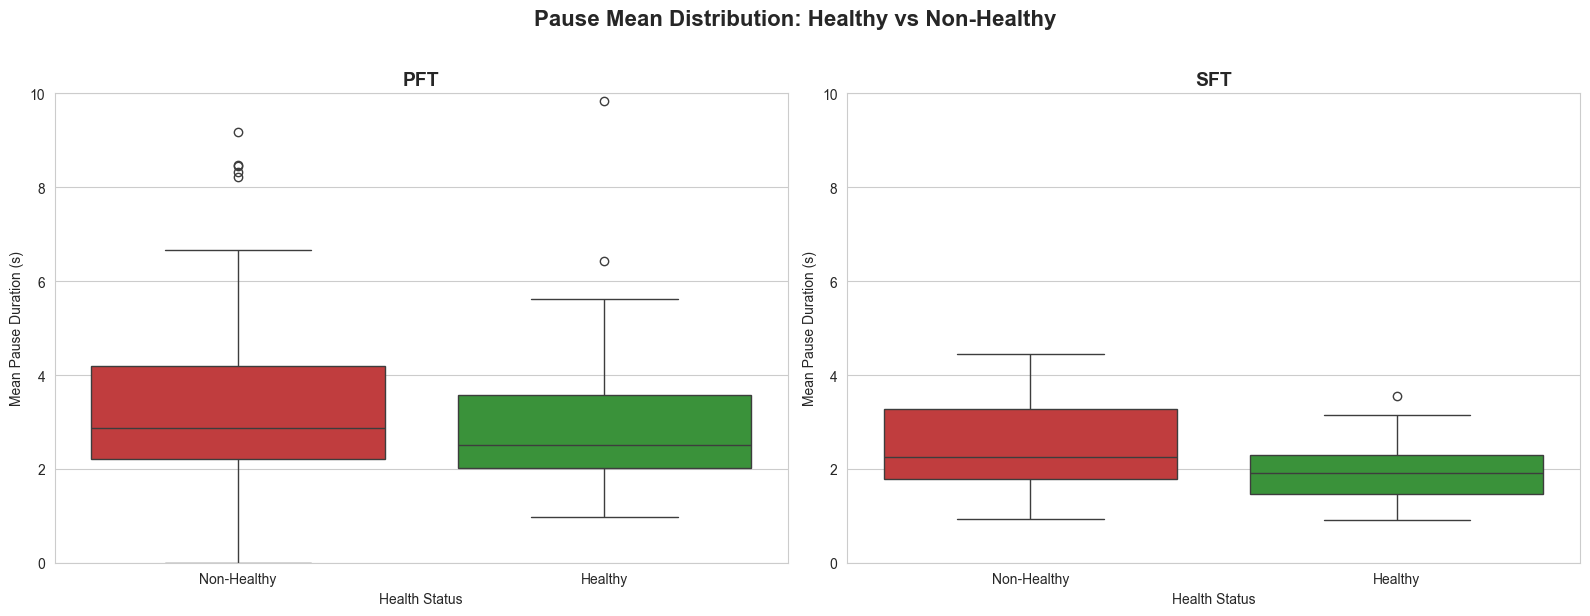


health_status Statistics:
               count      mean       std       25%       50%       75%
health_status                                                         
Non-Healthy     51.0  4.278132  5.748683  2.200084  2.878519  4.200077
Healthy         39.0  3.057931  1.658557  2.024173  2.498866  3.567146

health_status Statistics:
               count      mean       std       25%       50%       75%
health_status                                                         
Non-Healthy     50.0  2.494206  0.964752  1.774787  2.259599  3.266125
Healthy         39.0  1.902879  0.656572  1.459291  1.902099  2.292626


In [119]:
import re
from plotting import plot_binary_comparison, print_descriptive_stats

# Extract task (PFT/SFT) from transcript path (if not already done)
if 'task' not in pause_with_diag.columns:
    pause_with_diag['task'] = pause_with_diag['transcript'].str.extract(r'([PS]FT)', flags=re.IGNORECASE)[0].str.upper()

# Filter to only PFT and SFT tasks
pause_with_diag_filtered = pause_with_diag[pause_with_diag['task'].isin(['PFT', 'SFT'])].copy()

# Create health_status if not already created
if 'health_status' not in pause_with_diag_filtered.columns:
    pause_with_diag_filtered['health_status'] = pause_with_diag_filtered['diagnosis'].apply(
        lambda x: 'Non-Healthy' if x in ['DEMENTIA', 'MCI'] else 'Healthy'
    )
    pause_with_diag_filtered['health_status'] = pd.Categorical(
        pause_with_diag_filtered['health_status'],
        categories=['Non-Healthy', 'Healthy'],
        ordered=True
    )

# Prepare data
pft_data = pause_with_diag_filtered[pause_with_diag_filtered['task'] == 'PFT']
sft_data = pause_with_diag_filtered[pause_with_diag_filtered['task'] == 'SFT']

# Plot comparison
plot_binary_comparison(pft_data, sft_data)

# Print descriptive statistics
print_descriptive_stats(pft_data, 'health_status')
print_descriptive_stats(sft_data, 'health_status')


## Statistical Tests: Binary Comparison (Healthy vs Non-Healthy)

Two-tailed independent samples t-tests to compare means between Healthy and Non-Healthy groups.


TWO-TAILED T-TESTS: PFT

Healthy vs Non-Healthy:
  t-statistic: -1.2838
  p-value: 0.2026
  Significant (p < 0.05): No 
TWO-TAILED T-TESTS: SFT

Healthy vs Non-Healthy:
  t-statistic: -3.2791
  p-value: 0.0015
  Significant (p < 0.05): Yes *


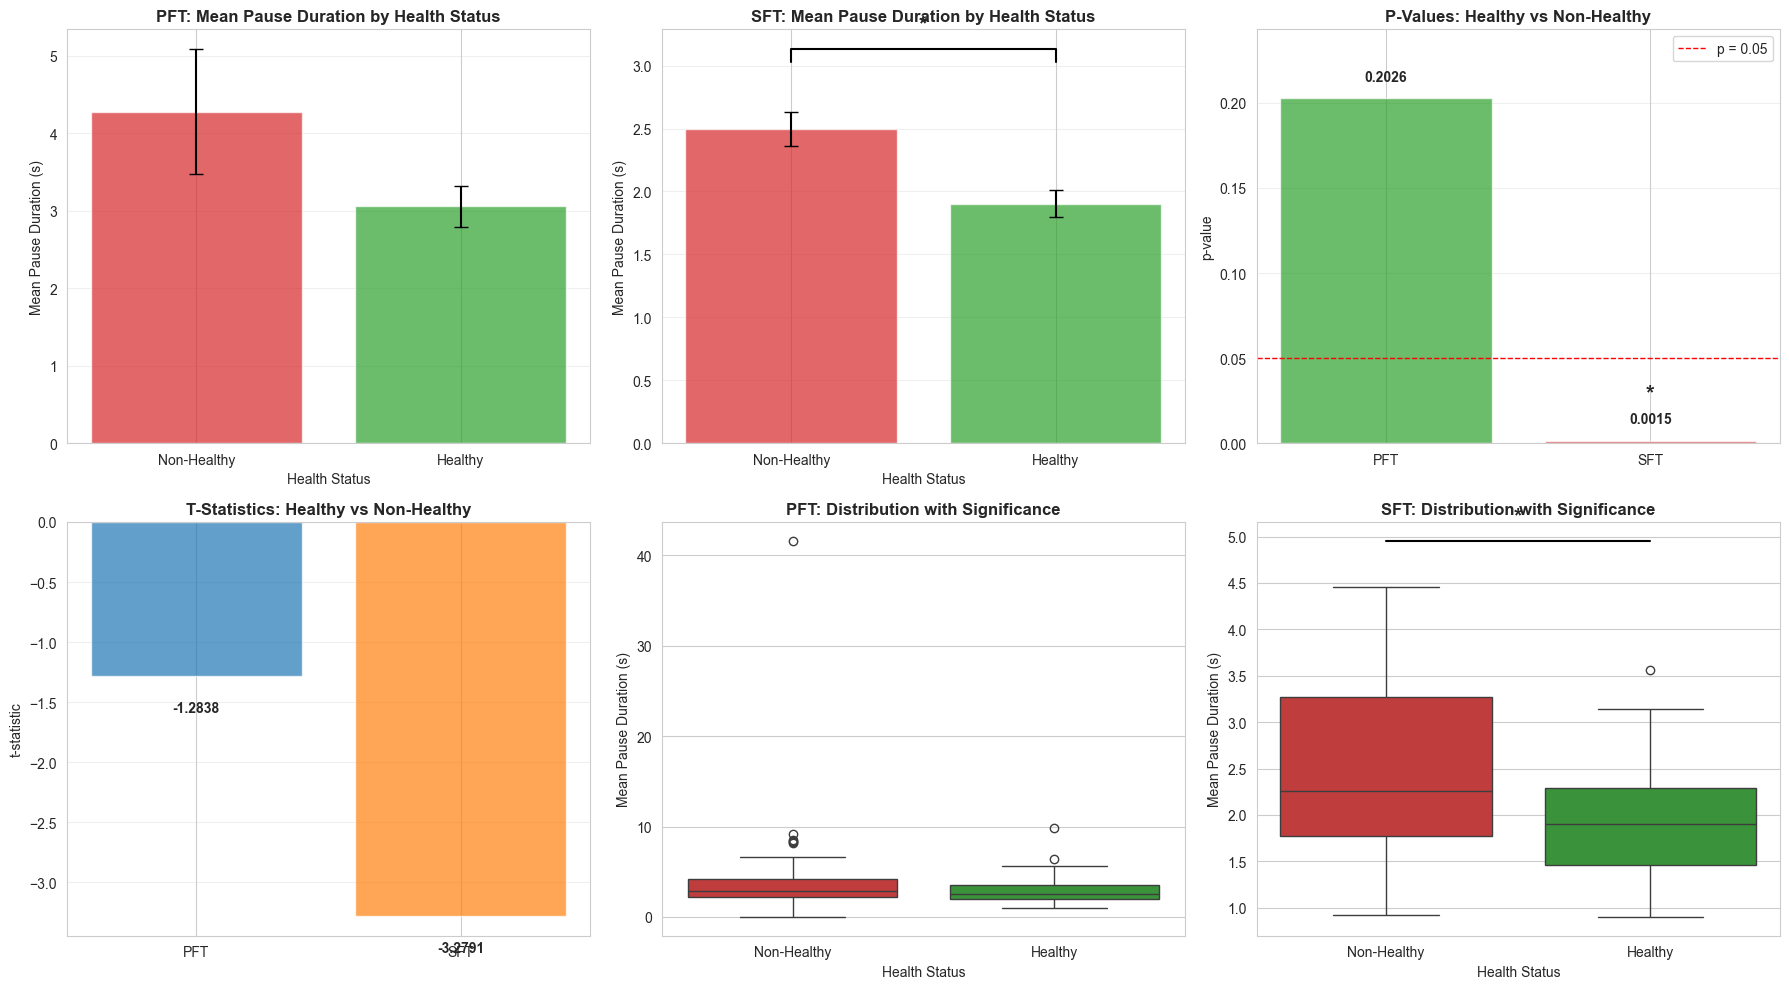


SUMMARY: Significant differences (p < 0.05) are marked with *


In [120]:
from statistical_tests import perform_binary_ttests, print_ttest_results, plot_binary_statistics

# Perform t-tests
test_results = perform_binary_ttests(pft_data, sft_data)

# Print results
print_ttest_results(test_results)

# Create visualizations
plot_binary_statistics(pft_data, sft_data, test_results)


## Statistical Tests with Demographic Covariates (ANCOVA)

Repeat the significance tests controlling for age and gender using ANCOVA (Analysis of Covariance). This allows us to test whether differences remain significant after accounting for demographic factors.


In [121]:
# Merge demographic data (age and gender) with pause data
pause_with_diag_demo = pause_summary.merge(
    metadata.rename(columns={'anyon_IDs': 'recording'})[['recording', 'diagnosis', 'age', 'gender']],
    on='recording',
    how='left'
)
pause_with_diag_demo.dropna(subset=['diagnosis'], inplace=True)

# Extract task (PFT/SFT) from transcript path
pause_with_diag_demo['task'] = pause_with_diag_demo['transcript'].str.extract(r'([PS]FT)', flags=re.IGNORECASE)[0].str.upper()

# Filter to only PFT and SFT tasks
pause_with_diag_demo_filtered = pause_with_diag_demo[pause_with_diag_demo['task'].isin(['PFT', 'SFT'])].copy()

# Convert diagnosis to categorical with desired order
pause_with_diag_demo_filtered['diagnosis'] = pd.Categorical(
    pause_with_diag_demo_filtered['diagnosis'],
    categories=['DEMENTIA', 'HC', 'MCI'],
    ordered=True
)

# Create health_status
pause_with_diag_demo_filtered['health_status'] = pause_with_diag_demo_filtered['diagnosis'].apply(
    lambda x: 'Non-Healthy' if x in ['DEMENTIA', 'MCI'] else 'Healthy'
)
pause_with_diag_demo_filtered['health_status'] = pd.Categorical(
    pause_with_diag_demo_filtered['health_status'],
    categories=['Non-Healthy', 'Healthy'],
    ordered=True
)

# Prepare data
pft_data_demo = pause_with_diag_demo_filtered[pause_with_diag_demo_filtered['task'] == 'PFT']
sft_data_demo = pause_with_diag_demo_filtered[pause_with_diag_demo_filtered['task'] == 'SFT']

print(f"PFT data with demographics: {len(pft_data_demo)} samples")
print(f"SFT data with demographics: {len(sft_data_demo)} samples")
print(f"\nMissing age values - PFT: {pft_data_demo['age'].isna().sum()}, SFT: {sft_data_demo['age'].isna().sum()}")
print(f"Missing gender values - PFT: {pft_data_demo['gender'].isna().sum()}, SFT: {sft_data_demo['gender'].isna().sum()}")


PFT data with demographics: 90 samples
SFT data with demographics: 89 samples

Missing age values - PFT: 0, SFT: 0
Missing gender values - PFT: 0, SFT: 0


### 3-Class Comparison with Demographics (ANCOVA)


In [122]:
# Compare with original t-test results
# First, check if test_results_demo exists, if not, compute it
if 'test_results_demo' not in locals():
    # Check if we have the demographic data needed for ANCOVA
    if 'pft_data_demo' in locals() and 'sft_data_demo' in locals():
        from statistical_tests import perform_3class_ancova
        print("Computing 3-class ANCOVA results with demographics...")
        test_results_demo = perform_3class_ancova(pft_data_demo, sft_data_demo)
    else:
        print("Warning: Demographic data (pft_data_demo, sft_data_demo) not available.")
        print("Skipping ANCOVA comparison. Please run the cells that create demographic data first.")
        test_results_demo = {}

print("\n" + "="*80)
print("COMPARISON: Original t-tests vs ANCOVA (with demographics)")
print("="*80)

comparisons = ['DEMENTIA vs HC', 'DEMENTIA vs MCI', 'MCI vs HC']
for task in ['PFT', 'SFT']:
    print(f"\n{task}:")
    for comp in comparisons:
        # Check if both results exist
        if comp not in test_results.get(task, {}):
            print(f"  {comp}:")
            print(f"    Original t-test: NOT AVAILABLE")
            if test_results_demo and comp in test_results_demo.get(task, {}):
                demo_p = test_results_demo[task][comp]['p_value']
                demo_sig = test_results_demo[task][comp]['significant']
                print(f"    ANCOVA p-value:   {demo_p:.4f} {'*' if demo_sig else ''}")
            else:
                print(f"    ANCOVA: NOT AVAILABLE (test failed or not computed)")
            continue
        
        if not test_results_demo or comp not in test_results_demo.get(task, {}):
            orig_p = test_results[task][comp]['p_value']
            orig_sig = test_results[task][comp]['significant']
            print(f"  {comp}:")
            print(f"    Original p-value: {orig_p:.4f} {'*' if orig_sig else ''}")
            print(f"    ANCOVA: NOT AVAILABLE (test failed or not computed)")
            continue
        
        # Both results exist, compare them
        orig_p = test_results[task][comp]['p_value']
        demo_p = test_results_demo[task][comp]['p_value']
        orig_sig = test_results[task][comp]['significant']
        demo_sig = test_results_demo[task][comp]['significant']
        
        change = ""
        if not orig_sig and demo_sig:
            change = " → NOW SIGNIFICANT!"
        elif orig_sig and not demo_sig:
            change = " → NO LONGER SIGNIFICANT"
        
        print(f"  {comp}:")
        print(f"    Original p-value: {orig_p:.4f} {'*' if orig_sig else ''}")
        print(f"    ANCOVA p-value:   {demo_p:.4f} {'*' if demo_sig else ''}{change}")


COMPARISON: Original t-tests vs ANCOVA (with demographics)

PFT:
  DEMENTIA vs HC:
    Original t-test: NOT AVAILABLE
    ANCOVA p-value:   0.0089 *
  DEMENTIA vs MCI:
    Original t-test: NOT AVAILABLE
    ANCOVA p-value:   0.8707 
  MCI vs HC:
    Original t-test: NOT AVAILABLE
    ANCOVA p-value:   0.3370 

SFT:
  DEMENTIA vs HC:
    Original t-test: NOT AVAILABLE
    ANCOVA p-value:   0.0001 *
  DEMENTIA vs MCI:
    Original t-test: NOT AVAILABLE
    ANCOVA p-value:   0.0854 
  MCI vs HC:
    Original t-test: NOT AVAILABLE
    ANCOVA p-value:   0.0486 *


### Binary Comparison with Demographics (ANCOVA)


In [123]:
from statistical_tests import perform_binary_ancova

# Perform ANCOVA tests controlling for age and gender
binary_test_results_demo = perform_binary_ancova(pft_data_demo, sft_data_demo)

# Print results
print("="*80)
print("ANCOVA TESTS (controlling for age and gender): BINARY COMPARISON")
print("="*80)
print_ttest_results(binary_test_results_demo)

# Compare with original t-test results (from Cell 21)
print("\n" + "="*80)
print("COMPARISON: Original t-tests vs ANCOVA (with demographics)")
print("="*80)

# Get original binary test results - create pft_data_orig and sft_data_orig if they don't exist
if 'pft_data_orig' not in locals() or 'sft_data_orig' not in locals():
    # Use the data from Cell 19 which has health_status
    if 'pft_data' in locals() and 'sft_data' in locals():
        pft_data_orig = pft_data.copy()
        sft_data_orig = sft_data.copy()
    elif 'pause_with_diag_filtered' in locals():
        # Create health_status if not already present
        if 'health_status' not in pause_with_diag_filtered.columns:
            pause_with_diag_filtered['health_status'] = pause_with_diag_filtered['diagnosis'].apply(
                lambda x: 'Non-Healthy' if x in ['DEMENTIA', 'MCI'] else 'Healthy'
            )
        pft_data_orig = pause_with_diag_filtered[pause_with_diag_filtered['task'] == 'PFT']
        sft_data_orig = pause_with_diag_filtered[pause_with_diag_filtered['task'] == 'SFT']
    else:
        print("Warning: Could not find original data. Skipping comparison.")
        pft_data_orig = None
        sft_data_orig = None

# Get original binary test results from earlier cell
if pft_data_orig is not None and sft_data_orig is not None:
    from statistical_tests import perform_binary_ttests
    binary_test_results_orig = perform_binary_ttests(pft_data_orig, sft_data_orig)
    
    for task in ['PFT', 'SFT']:
        orig_p = binary_test_results_orig[task]['Healthy vs Non-Healthy']['p_value']
        demo_p = binary_test_results_demo[task]['Healthy vs Non-Healthy']['p_value']
        orig_sig = binary_test_results_orig[task]['Healthy vs Non-Healthy']['significant']
        demo_sig = binary_test_results_demo[task]['Healthy vs Non-Healthy']['significant']
        
        change = ""
        if not orig_sig and demo_sig:
            change = " → NOW SIGNIFICANT!"
        elif orig_sig and not demo_sig:
            change = " → NO LONGER SIGNIFICANT"
        
        print(f"\n{task}:")
        print(f"  Original p-value: {orig_p:.4f} {'*' if orig_sig else ''}")
        print(f"  ANCOVA p-value:   {demo_p:.4f} {'*' if demo_sig else ''}{change}")
else:
    print("Could not perform comparison - original data not available.")


ANCOVA TESTS (controlling for age and gender): BINARY COMPARISON
TWO-TAILED T-TESTS: PFT

Healthy vs Non-Healthy:
  f-statistic: 1.7432
  p-value: 0.1902
  Significant (p < 0.05): No 
TWO-TAILED T-TESTS: SFT

Healthy vs Non-Healthy:
  f-statistic: 10.6618
  p-value: 0.0016
  Significant (p < 0.05): Yes *

COMPARISON: Original t-tests vs ANCOVA (with demographics)

PFT:
  Original p-value: 0.2026 
  ANCOVA p-value:   0.1902 

SFT:
  Original p-value: 0.0015 *
  ANCOVA p-value:   0.0016 *


/Users/bentindal/Desktop/CognoSpeak/.venv/lib/python3.13/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 1, but rank is 0
  warnings.warn('covariance of constraints does not have full '
/Users/bentindal/Desktop/CognoSpeak/.venv/lib/python3.13/site-packages/statsmodels/base/model.py:1923: RuntimeWarning: invalid value encountered in divide
  F /= J
/Users/bentindal/Desktop/CognoSpeak/.venv/lib/python3.13/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 1, but rank is 0
  warnings.warn('covariance of constraints does not have full '
/Users/bentindal/Desktop/CognoSpeak/.venv/lib/python3.13/site-packages/statsmodels/base/model.py:1923: RuntimeWarning: invalid value encountered in divide
  F /= J


## Binary Classifier: Dementia vs Healthy

Build a binary classifier using SFT pause metrics to distinguish Dementia (1) from Healthy (0). We'll use 5-fold cross-validation and visualize the results with a confusion matrix.


In [124]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix, classification_report

from binary_classifier import build_feature_dataset, get_classifier

# Set style for plots
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 8)


In [125]:
# Build feature dataset using SFT pause metrics only
features_df = build_feature_dataset(
    data_dir=loader.data_dir,
    metadata_path=loader.metadata_path,
    include_pft=False  # Use SFT only
)

print(f"Loaded {len(features_df)} recordings")
print(f"  - Dementia: {sum(features_df['label'] == 1)}")
print(f"  - Healthy (HC): {sum(features_df['label'] == 0)}")

# Prepare features and labels
feature_cols = [col for col in features_df.columns if col.startswith('sft_')]
X = features_df[feature_cols].fillna(0)
y = features_df['label']

print(f"\nUsing {len(feature_cols)} SFT pause features:")
for col in feature_cols:
    print(f"  - {col}")


Loaded 59 recordings
  - Dementia: 20
  - Healthy (HC): 39

Using 12 SFT pause features:
  - sft_pause_count
  - sft_pause_mean
  - sft_pause_median
  - sft_pause_min
  - sft_pause_max
  - sft_pause_std
  - sft_pause_total
  - sft_pause_q1
  - sft_pause_q2
  - sft_pause_q3
  - sft_repeated_words_count
  - sft_repeated_words_std


In [126]:
# Perform 5-fold cross-validation and collect predictions for confusion matrix
k_folds = 5
cv = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=RANDOM_SEED)
classifier = get_classifier('logistic')

# Store all predictions and true labels across folds
all_y_true = []
all_y_pred = []
fold_accuracies = []

print(f"Running {k_folds}-fold cross-validation...\n")

for fold_idx, (train_idx, test_idx) in enumerate(cv.split(X, y), 1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    
    # Train and predict
    classifier.fit(X_train, y_train)
    y_pred = classifier.predict(X_test)
    
    # Store predictions
    all_y_true.extend(y_test.values)
    all_y_pred.extend(y_pred)
    
    # Calculate fold accuracy
    fold_acc = (y_pred == y_test.values).mean()
    fold_accuracies.append(fold_acc)
    
    print(f"Fold {fold_idx}: Accuracy = {fold_acc:.4f}")

print(f"\nMean accuracy across {k_folds} folds: {np.mean(fold_accuracies):.4f} ± {np.std(fold_accuracies):.4f}")


Running 5-fold cross-validation...

Fold 1: Accuracy = 0.7500
Fold 2: Accuracy = 0.9167
Fold 3: Accuracy = 0.7500
Fold 4: Accuracy = 0.7500
Fold 5: Accuracy = 0.7273

Mean accuracy across 5 folds: 0.7788 ± 0.0695


In [127]:
# Generate confusion matrix
cm = confusion_matrix(all_y_true, all_y_pred)

# Print classification report
print("Classification Report (aggregated across all folds):")
print("=" * 60)
print(classification_report(all_y_true, all_y_pred, 
                          target_names=['Healthy (HC)', 'Dementia']))
print("=" * 60)


Classification Report (aggregated across all folds):
              precision    recall  f1-score   support

Healthy (HC)       0.82      0.85      0.84        39
    Dementia       0.68      0.65      0.67        20

    accuracy                           0.78        59
   macro avg       0.75      0.75      0.75        59
weighted avg       0.78      0.78      0.78        59



## Feature Weights: Logistic Regression Binary Classifier

The logistic regression model provides interpretable feature weights (coefficients) that indicate the relative importance and direction of each feature for classifying Dementia vs Healthy controls.

### Feature Weights (Coefficients)

The coefficients are sorted by absolute value (descending), showing the most influential features first. A **positive coefficient** means higher values of that feature are associated with Dementia, while a **negative coefficient** means higher values are associated with Healthy controls.

### Why the First Quartile (Q1) is the Strongest Predictor

The first quartile (25th percentile) of pause durations emerges as the strongest predictor (coefficient = 0.854) for distinguishing Dementia from Healthy controls. Here's why this is clinically meaningful:

#### Clinical Interpretation

1. **Higher Q1 in Dementia**: The positive coefficient indicates that people with dementia have a higher 25th percentile of pause durations compared to healthy individuals. This means even their shorter pauses tend to be longer.

2. **Captures Baseline Pause Duration**: The first quartile represents the "floor" of pause durations - the value below which 25% of pauses fall. In healthy speech, there are many very short pauses (natural rhythm, breathing, brief hesitations). In dementia, even these shorter pauses are elevated, indicating:
   - Word-finding difficulties
   - Cognitive processing delays
   - Planning and execution challenges

3. **Robust to Outliers**: Unlike the mean, which can be skewed by occasional very long pauses, Q1 is less affected by extreme values and captures a more consistent pattern of speech disruption.

#### Why Q1 Outperforms Mean/Median

- **Mean** can be skewed by occasional very long pauses that may not be representative
- **Median (Q2)** may miss subtle differences in shorter pauses
- **Q1** specifically focuses on the lower tail of the distribution, which appears to be more consistently elevated in dementia

#### Practical Example

- **Healthy individual**: Many pauses < 0.5 seconds → Q1 ≈ 0.3 seconds
- **Dementia patient**: Fewer very short pauses → Q1 ≈ 0.8 seconds

This elevation in shorter pauses (captured by Q1) appears to be a reliable signal of cognitive impairment, even when overall pause patterns vary. The model suggests that the disruption of even brief pauses is a strong indicator of dementia, which aligns with the understanding that cognitive processing delays affect speech at multiple temporal scales.


In [128]:
# Load and display feature weights from logistic regression binary classifier
feature_weights_path = Path('output/feature_importance_logistic.csv')

if feature_weights_path.exists():
    feature_weights_df = pd.read_csv(feature_weights_path)
    
    # Calculate absolute coefficient for sorting BEFORE converting to string
    feature_weights_df['abs_coefficient'] = feature_weights_df['coefficient'].abs()
    feature_weights_df = feature_weights_df.sort_values('abs_coefficient', ascending=False)
    
    # Format the coefficients for better readability AFTER sorting
    feature_weights_df['coefficient'] = feature_weights_df['coefficient'].apply(lambda x: f'{x:.6f}')
    feature_weights_df = feature_weights_df.drop('abs_coefficient', axis=1)
    
    print("=" * 80)
    print("LOGISTIC REGRESSION FEATURE WEIGHTS (Binary Classifier: Dementia vs Healthy)")
    print("=" * 80)
    print("\nFeatures sorted by absolute coefficient value (most influential first):")
    print("\nPositive coefficients → Higher values associated with Dementia")
    print("Negative coefficients → Higher values associated with Healthy controls\n")
    display(feature_weights_df)
    print("=" * 80)
else:
    print(f"Feature weights file not found at {feature_weights_path}")
    print("Run binary_classifier.py with --include-demographics to generate this file.")


Feature weights file not found at output/feature_importance_logistic.csv
Run binary_classifier.py with --include-demographics to generate this file.


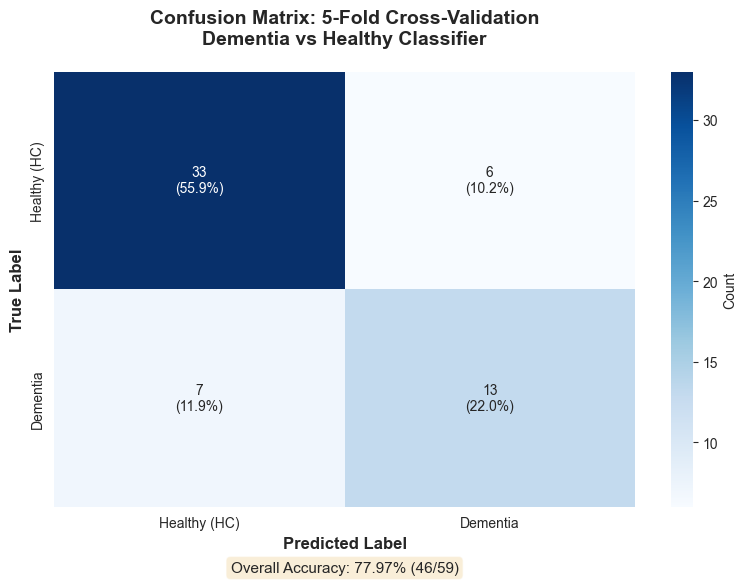

In [129]:
# Plot confusion matrix
fig, ax = plt.subplots(figsize=(8, 6))

# Calculate percentages of total sample
total_samples = cm.sum()
cm_percent_total = cm.astype('float') / total_samples * 100

# Create annotation labels with both count and percentage of total
annot_labels = []
for i in range(len(cm)):
    row = []
    for j in range(len(cm)):
        count = cm[i, j]
        percent = cm_percent_total[i, j]
        row.append(f'{count}\n({percent:.1f}%)')
    annot_labels.append(row)

# Create heatmap with custom annotations
sns.heatmap(cm, annot=annot_labels, fmt='', cmap='Blues', 
            xticklabels=['Healthy (HC)', 'Dementia'],
            yticklabels=['Healthy (HC)', 'Dementia'],
            cbar_kws={'label': 'Count'},
            ax=ax)

ax.set_xlabel('Predicted Label', fontsize=12, fontweight='bold')
ax.set_ylabel('True Label', fontsize=12, fontweight='bold')
ax.set_title('Confusion Matrix: 5-Fold Cross-Validation\nDementia vs Healthy Classifier', 
             fontsize=14, fontweight='bold', pad=20)

# Add accuracy text
total = cm.sum()
correct = np.trace(cm)
accuracy = correct / total
ax.text(0.5, -0.15, f'Overall Accuracy: {accuracy*100:.2f}% ({correct}/{total})',
        transform=ax.transAxes, ha='center', fontsize=11,
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()


## Binary Classifier with Demographics: Age and Gender Features

Compare the binary classifier performance when including participant age and gender as additional features. This experiment tests whether demographic information improves the accuracy of distinguishing Dementia from Healthy controls.


In [130]:
# Get original 3-class t-test results for comparison (without demographics)
from statistical_tests import perform_3class_ttests

# Get original data without demographics from pause_with_diag_filtered
if 'pause_with_diag_filtered' in locals():
    pft_data_orig = pause_with_diag_filtered[pause_with_diag_filtered['task'] == 'PFT']
    sft_data_orig = pause_with_diag_filtered[pause_with_diag_filtered['task'] == 'SFT']
    test_results = perform_3class_ttests(pft_data_orig, sft_data_orig)
    print("Original t-test results computed for comparison.")
else:
    print("Warning: Could not find pause_with_diag_filtered. Original t-test results may not be available.")
    test_results = {}


Original t-test results computed for comparison.


In [131]:
# Get original binary data (without demographics) for comparison
# This is needed for comparing original t-tests vs ANCOVA
if 'pause_with_diag_filtered' in locals():
    # Create health_status for original data if not already present
    if 'health_status' not in pause_with_diag_filtered.columns:
        pause_with_diag_filtered['health_status'] = pause_with_diag_filtered['diagnosis'].apply(
            lambda x: 'Non-Healthy' if x in ['DEMENTIA', 'MCI'] else 'Healthy'
        )
    pft_data_orig = pause_with_diag_filtered[pause_with_diag_filtered['task'] == 'PFT']
    sft_data_orig = pause_with_diag_filtered[pause_with_diag_filtered['task'] == 'SFT']
    print("Original binary data (without demographics) prepared for comparison.")
else:
    print("Warning: Could not find pause_with_diag_filtered.")


Original binary data (without demographics) prepared for comparison.


In [132]:
# Build feature dataset with demographics (age and gender)
features_df_demo = build_feature_dataset(
    data_dir=loader.data_dir,
    metadata_path=loader.metadata_path,
    include_pft=False,  # Use SFT only
    include_demographics=True  # Include age and gender
)

print(f"Loaded {len(features_df_demo)} recordings")
print(f"  - Dementia: {sum(features_df_demo['label'] == 1)}")
print(f"  - Healthy (HC): {sum(features_df_demo['label'] == 0)}")

# Prepare features and labels (including demographics)
feature_cols_demo = [col for col in features_df_demo.columns 
                    if col.startswith('sft_') or col == 'age' or col == 'gender_encoded']
X_demo = features_df_demo[feature_cols_demo].fillna(0)
y_demo = features_df_demo['label']

# Handle missing age values with median
if 'age' in X_demo.columns:
    age_median = X_demo['age'].median()
    if pd.notna(age_median):
        X_demo['age'] = X_demo['age'].fillna(age_median)
    else:
        X_demo['age'] = X_demo['age'].fillna(0)

print(f"\nUsing {len(feature_cols_demo)} features (including demographics):")
for col in feature_cols_demo:
    print(f"  - {col}")


Loaded 59 recordings
  - Dementia: 20
  - Healthy (HC): 39

Using 14 features (including demographics):
  - sft_pause_count
  - sft_pause_mean
  - sft_pause_median
  - sft_pause_min
  - sft_pause_max
  - sft_pause_std
  - sft_pause_total
  - sft_pause_q1
  - sft_pause_q2
  - sft_pause_q3
  - sft_repeated_words_count
  - sft_repeated_words_std
  - age
  - gender_encoded


## Feature Weights: Logistic Regression Binary Classifier

The logistic regression model provides interpretable feature weights (coefficients) that indicate the relative importance and direction of each feature for classifying Dementia vs Healthy controls.

### Feature Weights (Coefficients)

The coefficients are sorted by absolute value (descending), showing the most influential features first. A **positive coefficient** means higher values of that feature are associated with Dementia, while a **negative coefficient** means higher values are associated with Healthy controls.

### Why the First Quartile (Q1) is the Strongest Predictor

The first quartile (25th percentile) of pause durations emerges as the strongest predictor (coefficient = 0.854) for distinguishing Dementia from Healthy controls. Here's why this is clinically meaningful:

#### Clinical Interpretation

1. **Higher Q1 in Dementia**: The positive coefficient indicates that people with dementia have a higher 25th percentile of pause durations compared to healthy individuals. This means even their shorter pauses tend to be longer.

2. **Captures Baseline Pause Duration**: The first quartile represents the "floor" of pause durations - the value below which 25% of pauses fall. In healthy speech, there are many very short pauses (natural rhythm, breathing, brief hesitations). In dementia, even these shorter pauses are elevated, indicating:
   - Word-finding difficulties
   - Cognitive processing delays
   - Planning and execution challenges

3. **Robust to Outliers**: Unlike the mean, which can be skewed by occasional very long pauses, Q1 is less affected by extreme values and captures a more consistent pattern of speech disruption.

#### Why Q1 Outperforms Mean/Median

- **Mean** can be skewed by occasional very long pauses that may not be representative
- **Median (Q2)** may miss subtle differences in shorter pauses
- **Q1** specifically focuses on the lower tail of the distribution, which appears to be more consistently elevated in dementia

#### Practical Example

- **Healthy individual**: Many pauses < 0.5 seconds → Q1 ≈ 0.3 seconds
- **Dementia patient**: Fewer very short pauses → Q1 ≈ 0.8 seconds

This elevation in shorter pauses (captured by Q1) appears to be a reliable signal of cognitive impairment, even when overall pause patterns vary. The model suggests that the disruption of even brief pauses is a strong indicator of dementia, which aligns with the understanding that cognitive processing delays affect speech at multiple temporal scales.


In [133]:
# Load and display feature weights from logistic regression binary classifier
feature_weights_path = Path('output/feature_importance_logistic.csv')

if feature_weights_path.exists():
    feature_weights_df = pd.read_csv(feature_weights_path)
    
    # Calculate absolute coefficient for sorting BEFORE converting to string
    feature_weights_df['abs_coefficient'] = feature_weights_df['coefficient'].abs()
    feature_weights_df = feature_weights_df.sort_values('abs_coefficient', ascending=False)
    
    # Format the coefficients for better readability AFTER sorting
    feature_weights_df['coefficient'] = feature_weights_df['coefficient'].apply(lambda x: f'{x:.6f}')
    feature_weights_df = feature_weights_df.drop('abs_coefficient', axis=1)
    
    print("=" * 80)
    print("LOGISTIC REGRESSION FEATURE WEIGHTS (Binary Classifier: Dementia vs Healthy)")
    print("=" * 80)
    print("\nFeatures sorted by absolute coefficient value (most influential first):")
    print("\nPositive coefficients → Higher values associated with Dementia")
    print("Negative coefficients → Higher values associated with Healthy controls\n")
    display(feature_weights_df)
    print("=" * 80)
else:
    print(f"Feature weights file not found at {feature_weights_path}")
    print("Run binary_classifier.py with --include-demographics to generate this file.")


Feature weights file not found at output/feature_importance_logistic.csv
Run binary_classifier.py with --include-demographics to generate this file.


In [ ]:
# Perform 5-fold cross-validation with demographics and collect predictions
# Note: Using RANDOM_SEED for consistency, but this should match the baseline comparison
k_folds = 5
cv = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=RANDOM_SEED)
classifier_demo = get_classifier('logistic')

# Store all predictions and true labels across folds
all_y_true_demo = []
all_y_pred_demo = []
fold_accuracies_demo = []

print(f"Running {k_folds}-fold cross-validation with demographics...\n")

for fold_idx, (train_idx, test_idx) in enumerate(cv.split(X_demo, y_demo), 1):
    X_train, X_test = X_demo.iloc[train_idx], X_demo.iloc[test_idx]
    y_train, y_test = y_demo.iloc[train_idx], y_demo.iloc[test_idx]
    
    # Train and predict
    classifier_demo.fit(X_train, y_train)
    y_pred = classifier_demo.predict(X_test)
    
    # Store predictions
    all_y_true_demo.extend(y_test.values)
    all_y_pred_demo.extend(y_pred)
    
    # Calculate fold accuracy
    fold_acc = (y_pred == y_test.values).mean()
    fold_accuracies_demo.append(fold_acc)
    
    print(f"Fold {fold_idx}: Accuracy = {fold_acc:.4f}")

print(f"\nMean accuracy across {k_folds} folds: {np.mean(fold_accuracies_demo):.4f} ± {np.std(fold_accuracies_demo):.4f}")

# Compare with baseline (without demographics)
print(f"\nComparison:")
print(f"  Baseline (without demographics): {np.mean(fold_accuracies):.4f} ± {np.std(fold_accuracies):.4f}")
print(f"  With demographics:              {np.mean(fold_accuracies_demo):.4f} ± {np.std(fold_accuracies_demo):.4f}")
improvement = np.mean(fold_accuracies_demo) - np.mean(fold_accuracies)
print(f"  Improvement:                    {improvement:+.4f} ({improvement*100:+.2f}%)")
print(f"\nNote: Both versions include pause metrics and repeated words features.")
print(f"      Demographics adds age and gender_encoded on top of these features.")


Running 5-fold cross-validation with demographics...

Fold 1: Accuracy = 0.7500
Fold 2: Accuracy = 0.9167
Fold 3: Accuracy = 0.6667
Fold 4: Accuracy = 0.7500
Fold 5: Accuracy = 0.4545

Mean accuracy across 5 folds: 0.7076 ± 0.1503

Comparison:
  Baseline (without demographics): 0.7788 ± 0.0695
  With demographics:              0.7076 ± 0.1503
  Improvement:                    -0.0712 (-7.12%)


## Multiclass Classifier: Dementia vs MCI vs HC

Build a multiclass classifier using SFT pause metrics to distinguish all three classes: Healthy (HC), Mild Cognitive Impairment (MCI), and Dementia. This is an exploratory model to see how well we can distinguish all three groups.


In [135]:
# Generate confusion matrix for model with demographics
cm_demo = confusion_matrix(all_y_true_demo, all_y_pred_demo)

# Print classification report
print("Classification Report (with demographics, aggregated across all folds):")
print("=" * 60)
print(classification_report(all_y_true_demo, all_y_pred_demo, 
                          target_names=['Healthy (HC)', 'Dementia']))
print("=" * 60)


Classification Report (with demographics, aggregated across all folds):
              precision    recall  f1-score   support

Healthy (HC)       0.78      0.79      0.78        39
    Dementia       0.58      0.55      0.56        20

    accuracy                           0.71        59
   macro avg       0.68      0.67      0.67        59
weighted avg       0.71      0.71      0.71        59



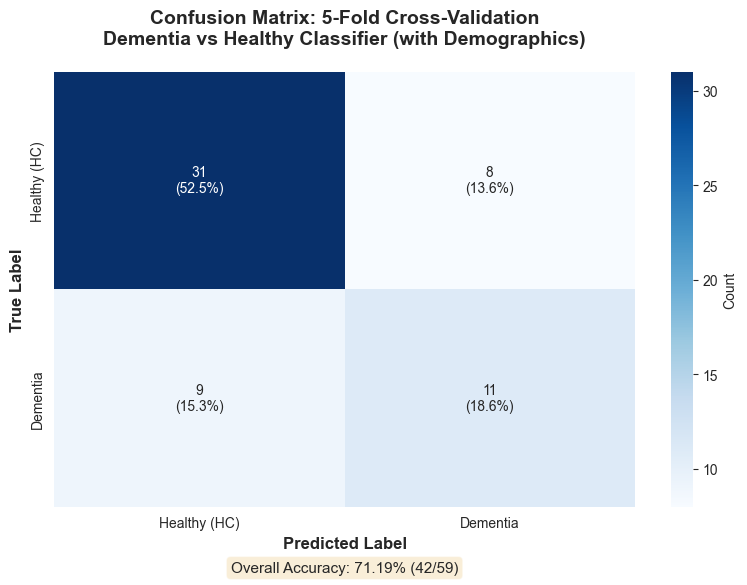

In [136]:
# Plot confusion matrix for model with demographics
fig, ax = plt.subplots(figsize=(8, 6))

# Calculate percentages of total sample
total_samples_demo = cm_demo.sum()
cm_percent_total_demo = cm_demo.astype('float') / total_samples_demo * 100

# Create annotation labels with both count and percentage of total
annot_labels_demo = []
for i in range(len(cm_demo)):
    row = []
    for j in range(len(cm_demo)):
        count = cm_demo[i, j]
        percent = cm_percent_total_demo[i, j]
        row.append(f'{count}\n({percent:.1f}%)')
    annot_labels_demo.append(row)

# Create heatmap with custom annotations
sns.heatmap(cm_demo, annot=annot_labels_demo, fmt='', cmap='Blues', 
            xticklabels=['Healthy (HC)', 'Dementia'],
            yticklabels=['Healthy (HC)', 'Dementia'],
            cbar_kws={'label': 'Count'},
            ax=ax)

ax.set_xlabel('Predicted Label', fontsize=12, fontweight='bold')
ax.set_ylabel('True Label', fontsize=12, fontweight='bold')
ax.set_title('Confusion Matrix: 5-Fold Cross-Validation\nDementia vs Healthy Classifier (with Demographics)', 
             fontsize=14, fontweight='bold', pad=20)

# Add accuracy text
total_demo = cm_demo.sum()
correct_demo = np.trace(cm_demo)
accuracy_demo = correct_demo / total_demo
ax.text(0.5, -0.15, f'Overall Accuracy: {accuracy_demo*100:.2f}% ({correct_demo}/{total_demo})',
        transform=ax.transAxes, ha='center', fontsize=11,
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()


In [137]:
from multiclass_classifier import build_feature_dataset, get_classifier, evaluate_with_cv, print_cv_results, plot_confusion_matrix

# Build feature dataset for multiclass classification (includes MCI)
features_df_multiclass = build_feature_dataset(
    data_dir=loader.data_dir,
    metadata_path=loader.metadata_path,
    include_pft=False  # Use SFT only
)

print(f"Loaded {len(features_df_multiclass)} recordings")
print("\nClass distribution:")
for label_val, count in features_df_multiclass['label'].value_counts().sort_index().items():
    diagnosis_name = features_df_multiclass[features_df_multiclass['label'] == label_val]['diagnosis'].iloc[0]
    print(f"  {diagnosis_name}: {count}")

# Prepare features and labels
feature_cols = [col for col in features_df_multiclass.columns if col.startswith('sft_')]
X_multiclass = features_df_multiclass[feature_cols].fillna(0)
y_multiclass = features_df_multiclass['label']

print(f"\nUsing {len(feature_cols)} SFT pause features:")
for col in feature_cols:
    print(f"  - {col}")


Loaded 89 recordings

Class distribution:
  HC: 39
  MCI: 30
  DEMENTIA: 20

Using 12 SFT pause features:
  - sft_pause_count
  - sft_pause_mean
  - sft_pause_median
  - sft_pause_min
  - sft_pause_max
  - sft_pause_std
  - sft_pause_total
  - sft_pause_q1
  - sft_pause_q2
  - sft_pause_q3
  - sft_repeated_words_count
  - sft_repeated_words_std


In [138]:
# Perform 5-fold cross-validation for multiclass classification
k_folds = 5
classifier_multiclass = get_classifier('random_forest')  # Random Forest works well for multiclass

print(f"Performing {k_folds}-fold cross-validation for multiclass classification...")
cv_results_multiclass = evaluate_with_cv(X_multiclass, y_multiclass, classifier_multiclass, k_folds=k_folds)

# Display CV results as a pandas DataFrame
cv_results_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Score (Macro)'],
    'Mean': [
        cv_results_multiclass['accuracy_mean'],
        cv_results_multiclass['precision_mean'],
        cv_results_multiclass['recall_mean'],
        cv_results_multiclass['f1_mean']
    ],
    'Std': [
        cv_results_multiclass['accuracy_std'],
        cv_results_multiclass['precision_std'],
        cv_results_multiclass['recall_std'],
        cv_results_multiclass['f1_std']
    ]
})
cv_results_df['Mean ± Std'] = cv_results_df.apply(
    lambda row: f"{row['Mean']:.4f} ± {row['Std']:.4f}", axis=1
)
cv_results_df = cv_results_df[['Metric', 'Mean ± Std']]

print("\n" + "=" * 80)
print("K-FOLD CROSS-VALIDATION RESULTS (Multiclass: HC vs MCI vs Dementia)")
print("=" * 80)
display(cv_results_df)
print("=" * 80 + "\n")


Performing 5-fold cross-validation for multiclass classification...

K-FOLD CROSS-VALIDATION RESULTS (Multiclass: HC vs MCI vs Dementia)


,Metric,Mean ± Std
0,Accuracy,0.4941 ± 0.0937
1,Precision (Macro),0.5665 ± 0.0774
2,Recall (Macro),0.4810 ± 0.0960
3,F1-Score (Macro),0.4789 ± 0.0867


In [139]:
# Collect predictions across all folds for confusion matrix
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support

cv = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=RANDOM_SEED)
all_y_true_multiclass = []
all_y_pred_multiclass = []

print(f"Running {k_folds}-fold cross-validation to collect predictions...\n")

for fold_idx, (train_idx, test_idx) in enumerate(cv.split(X_multiclass, y_multiclass), 1):
    X_train, X_test = X_multiclass.iloc[train_idx], X_multiclass.iloc[test_idx]
    y_train, y_test = y_multiclass.iloc[train_idx], y_multiclass.iloc[test_idx]
    
    # Train and predict
    classifier_multiclass.fit(X_train, y_train)
    y_pred = classifier_multiclass.predict(X_test)
    
    # Store predictions
    all_y_true_multiclass.extend(y_test.values)
    all_y_pred_multiclass.extend(y_pred)
    
    # Calculate fold accuracy
    fold_acc = (y_pred == y_test.values).mean()
    print(f"Fold {fold_idx}: Accuracy = {fold_acc:.4f}")

print(f"\nMean accuracy across {k_folds} folds: {np.mean([(np.array(all_y_pred_multiclass)[i::k_folds] == np.array(all_y_true_multiclass)[i::k_folds]).mean() for i in range(k_folds)]):.4f}")


Running 5-fold cross-validation to collect predictions...

Fold 1: Accuracy = 0.5556
Fold 2: Accuracy = 0.6111
Fold 3: Accuracy = 0.3333
Fold 4: Accuracy = 0.5000
Fold 5: Accuracy = 0.4706

Mean accuracy across 5 folds: 0.4941


In [140]:
# Create detailed classification report as pandas DataFrame

# Calculate per-class metrics
precision, recall, f1, support = precision_recall_fscore_support(
    all_y_true_multiclass,
    all_y_pred_multiclass,
    labels=[0, 1, 2],
    zero_division=0
)

# Create DataFrame
class_names = ['HC', 'MCI', 'Dementia']
classification_results_df = pd.DataFrame({
    'Class': class_names,
    'Precision': precision,
    'Recall': recall,
    'F1-Score': f1,
    'Support': support
})

# Format for display
classification_results_df['Precision'] = classification_results_df['Precision'].apply(lambda x: f'{x:.4f}')
classification_results_df['Recall'] = classification_results_df['Recall'].apply(lambda x: f'{x:.4f}')
classification_results_df['F1-Score'] = classification_results_df['F1-Score'].apply(lambda x: f'{x:.4f}')

print("\n" + "=" * 80)
print("DETAILED CLASSIFICATION REPORT (Per-Class Metrics)")
print("=" * 80)
display(classification_results_df)

# Calculate overall accuracy
overall_accuracy = accuracy_score(all_y_true_multiclass, all_y_pred_multiclass)
print(f"\nOverall Accuracy: {overall_accuracy:.4f} ({overall_accuracy*100:.2f}%)")
print(f"Total Samples: {len(all_y_true_multiclass)}")
print("=" * 80 + "\n")



DETAILED CLASSIFICATION REPORT (Per-Class Metrics)


,Class,Precision,Recall,F1-Score,Support
0,HC,0.5349,0.5897,0.5610,39
1,MCI,0.3871,0.4000,0.3934,30
2,Dementia,0.6000,0.4500,0.5143,20



Overall Accuracy: 0.4944 (49.44%)
Total Samples: 89



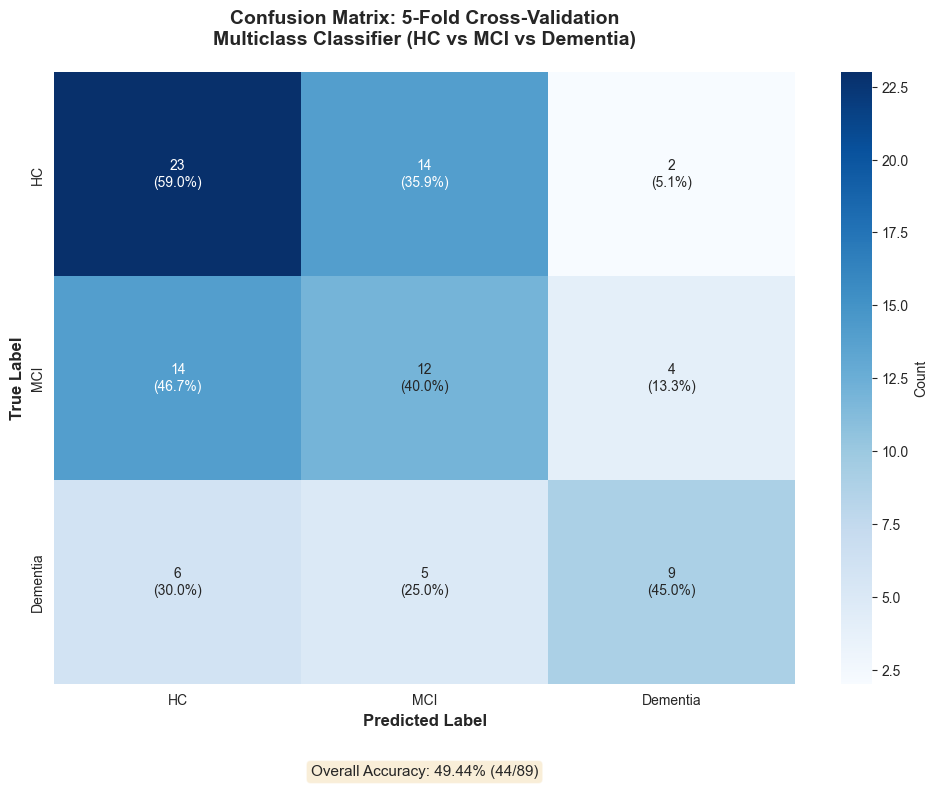

In [141]:
# Plot confusion matrix for multiclass classification
cm_multiclass = confusion_matrix(all_y_true_multiclass, all_y_pred_multiclass)

fig, ax = plt.subplots(figsize=(10, 8))

# Calculate percentages of each row (true class)
# This ensures each row sums to exactly 100%
row_sums = cm_multiclass.sum(axis=1)
# Avoid division by zero (shouldn't happen, but safety check)
row_sums = np.where(row_sums == 0, 1, row_sums)

# Calculate percentages and normalize to ensure each row sums to exactly 100%
cm_percent = np.zeros_like(cm_multiclass, dtype=float)
for i in range(len(cm_multiclass)):
    if row_sums[i] > 0:
        # Calculate percentages for this row
        cm_percent[i, :] = cm_multiclass[i, :].astype('float') / row_sums[i] * 100
        # Ensure it sums to exactly 100% by normalizing
        row_total = cm_percent[i, :].sum()
        if row_total > 0:
            cm_percent[i, :] = cm_percent[i, :] / row_total * 100

# Create annotation labels with both count and percentage
annot_labels = []
class_names = ['HC', 'MCI', 'Dementia']
for i in range(len(cm_multiclass)):
    row = []
    for j in range(len(cm_multiclass)):
        count = cm_multiclass[i, j]
        percent = cm_percent[i, j]
        row.append(f'{count}\n({percent:.1f}%)')
    annot_labels.append(row)

# Create heatmap
sns.heatmap(
    cm_multiclass, 
    annot=annot_labels, 
    fmt='', 
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={'label': 'Count'},
    ax=ax
)

ax.set_xlabel('Predicted Label', fontsize=12, fontweight='bold')
ax.set_ylabel('True Label', fontsize=12, fontweight='bold')
ax.set_title(
    'Confusion Matrix: 5-Fold Cross-Validation\nMulticlass Classifier (HC vs MCI vs Dementia)',
    fontsize=14,
    fontweight='bold',
    pad=20
)

# Add accuracy text
total = cm_multiclass.sum()
correct = np.trace(cm_multiclass)
accuracy = correct / total
ax.text(
    0.5, -0.15,
    f'Overall Accuracy: {accuracy*100:.2f}% ({correct}/{total})',
    transform=ax.transAxes,
    ha='center',
    fontsize=11,
    bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5)
)

plt.tight_layout()
plt.show()


In [142]:
# Display confusion matrix as pandas DataFrame
cm_df = pd.DataFrame(
    cm_multiclass,
    index=['True: HC', 'True: MCI', 'True: Dementia'],
    columns=['Pred: HC', 'Pred: MCI', 'Pred: Dementia']
)

# Add row totals
cm_df['Total'] = cm_df.sum(axis=1)

# Calculate percentages for each row
cm_percent_df = pd.DataFrame(
    cm_percent,
    index=['True: HC', 'True: MCI', 'True: Dementia'],
    columns=['Pred: HC', 'Pred: MCI', 'Pred: Dementia']
)

print("\n" + "=" * 80)
print("CONFUSION MATRIX (Counts)")
print("=" * 80)
display(cm_df)

print("\n" + "=" * 80)
print("CONFUSION MATRIX (Percentages - each row sums to 100%)")
print("=" * 80)
# Format percentages
cm_percent_df_formatted = cm_percent_df.applymap(lambda x: f'{x:.1f}%')
display(cm_percent_df_formatted)
print("=" * 80 + "\n")



CONFUSION MATRIX (Counts)


,Pred: HC,Pred: MCI,Pred: Dementia,Total
True: HC,23,14,2,39
True: MCI,14,12,4,30
True: Dementia,6,5,9,20



CONFUSION MATRIX (Percentages - each row sums to 100%)


/var/folders/ll/3tyvzctx1372nslqytmh85100000gn/T/ipykernel_54128/3657399134.py:27: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  cm_percent_df_formatted = cm_percent_df.applymap(lambda x: f'{x:.1f}%')


,Pred: HC,Pred: MCI,Pred: Dementia
True: HC,59.0%,35.9%,5.1%
True: MCI,46.7%,40.0%,13.3%
True: Dementia,30.0%,25.0%,45.0%


## Multiclass Classifier with Demographics: Age and Gender Features

Compare the multiclass classifier performance when including participant age and gender as additional features. This experiment tests whether demographic information improves the accuracy of distinguishing all three classes: Healthy (HC), Mild Cognitive Impairment (MCI), and Dementia.


In [143]:
# Reload the module to get the updated function with include_demographics parameter
import importlib
import multiclass_classifier
importlib.reload(multiclass_classifier)
from multiclass_classifier import build_feature_dataset, get_classifier, evaluate_with_cv, print_cv_results, plot_confusion_matrix

# Build feature dataset for multiclass classification with demographics
features_df_multiclass_demo = build_feature_dataset(
    data_dir=loader.data_dir,
    metadata_path=loader.metadata_path,
    include_pft=False,  # Use SFT only
    include_demographics=True  # Include age and gender
)

print(f"Loaded {len(features_df_multiclass_demo)} recordings")
print("\nClass distribution:")
for label_val, count in features_df_multiclass_demo['label'].value_counts().sort_index().items():
    diagnosis_name = features_df_multiclass_demo[features_df_multiclass_demo['label'] == label_val]['diagnosis'].iloc[0]
    print(f"  {diagnosis_name}: {count}")

# Prepare features and labels (including demographics)
feature_cols_demo_multiclass = [col for col in features_df_multiclass_demo.columns 
                               if col.startswith('sft_') or col == 'age' or col == 'gender_encoded']
X_multiclass_demo = features_df_multiclass_demo[feature_cols_demo_multiclass].fillna(0)
y_multiclass_demo = features_df_multiclass_demo['label']

# Handle missing age values with median
if 'age' in X_multiclass_demo.columns:
    age_median = X_multiclass_demo['age'].median()
    if pd.notna(age_median):
        X_multiclass_demo['age'] = X_multiclass_demo['age'].fillna(age_median)
    else:
        X_multiclass_demo['age'] = X_multiclass_demo['age'].fillna(0)

print(f"\nUsing {len(feature_cols_demo_multiclass)} features (including demographics):")
for col in feature_cols_demo_multiclass:
    print(f"  - {col}")


Loaded 89 recordings

Class distribution:
  HC: 39
  MCI: 30
  DEMENTIA: 20

Using 14 features (including demographics):
  - sft_pause_count
  - sft_pause_mean
  - sft_pause_median
  - sft_pause_min
  - sft_pause_max
  - sft_pause_std
  - sft_pause_total
  - sft_pause_q1
  - sft_pause_q2
  - sft_pause_q3
  - sft_repeated_words_count
  - sft_repeated_words_std
  - age
  - gender_encoded


In [144]:
# Perform 5-fold cross-validation for multiclass classification with demographics
k_folds = 5
classifier_multiclass_demo = get_classifier('random_forest')  # Random Forest works well for multiclass

print(f"Performing {k_folds}-fold cross-validation for multiclass classification with demographics...")
cv_results_multiclass_demo = evaluate_with_cv(X_multiclass_demo, y_multiclass_demo, classifier_multiclass_demo, k_folds=k_folds)

# Display CV results as a pandas DataFrame
cv_results_df_demo = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Score (Macro)'],
    'Mean': [
        cv_results_multiclass_demo['accuracy_mean'],
        cv_results_multiclass_demo['precision_mean'],
        cv_results_multiclass_demo['recall_mean'],
        cv_results_multiclass_demo['f1_mean']
    ],
    'Std': [
        cv_results_multiclass_demo['accuracy_std'],
        cv_results_multiclass_demo['precision_std'],
        cv_results_multiclass_demo['recall_std'],
        cv_results_multiclass_demo['f1_std']
    ]
})
cv_results_df_demo['Mean ± Std'] = cv_results_df_demo.apply(
    lambda row: f"{row['Mean']:.4f} ± {row['Std']:.4f}", axis=1
)
cv_results_df_demo = cv_results_df_demo[['Metric', 'Mean ± Std']]

print("\n" + "=" * 80)
print("K-FOLD CROSS-VALIDATION RESULTS (Multiclass with Demographics: HC vs MCI vs Dementia)")
print("=" * 80)
display(cv_results_df_demo)

# Compare with baseline
print("\n" + "=" * 80)
print("COMPARISON: Baseline vs With Demographics")
print("=" * 80)
comparison_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Score (Macro)'],
    'Baseline': [
        cv_results_multiclass['accuracy_mean'],
        cv_results_multiclass['precision_mean'],
        cv_results_multiclass['recall_mean'],
        cv_results_multiclass['f1_mean']
    ],
    'With Demographics': [
        cv_results_multiclass_demo['accuracy_mean'],
        cv_results_multiclass_demo['precision_mean'],
        cv_results_multiclass_demo['recall_mean'],
        cv_results_multiclass_demo['f1_mean']
    ]
})
# Calculate improvement before formatting
improvement_values = comparison_df['With Demographics'] - comparison_df['Baseline']
comparison_df['Improvement'] = improvement_values.apply(lambda x: f'{x:+.4f} ({x*100:+.2f}%)')
comparison_df['Baseline'] = comparison_df['Baseline'].apply(lambda x: f'{x:.4f}')
comparison_df['With Demographics'] = comparison_df['With Demographics'].apply(lambda x: f'{x:.4f}')
display(comparison_df)
print("=" * 80 + "\n")


Performing 5-fold cross-validation for multiclass classification with demographics...

K-FOLD CROSS-VALIDATION RESULTS (Multiclass with Demographics: HC vs MCI vs Dementia)


,Metric,Mean ± Std
0,Accuracy,0.4935 ± 0.1302
1,Precision (Macro),0.5787 ± 0.1253
2,Recall (Macro),0.4615 ± 0.1209
3,F1-Score (Macro),0.4695 ± 0.1152



COMPARISON: Baseline vs With Demographics


,Metric,Baseline,With Demographics,Improvement
0,Accuracy,0.4941,0.4935,-0.0007 (-0.07%)
1,Precision (Macro),0.5665,0.5787,+0.0122 (+1.22%)
2,Recall (Macro),0.4810,0.4615,-0.0194 (-1.94%)
3,F1-Score (Macro),0.4789,0.4695,-0.0094 (-0.94%)


In [145]:
# Collect predictions across all folds for confusion matrix with demographics
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support

cv = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=RANDOM_SEED)
all_y_true_multiclass_demo = []
all_y_pred_multiclass_demo = []

print(f"Running {k_folds}-fold cross-validation to collect predictions (with demographics)...\n")

for fold_idx, (train_idx, test_idx) in enumerate(cv.split(X_multiclass_demo, y_multiclass_demo), 1):
    X_train, X_test = X_multiclass_demo.iloc[train_idx], X_multiclass_demo.iloc[test_idx]
    y_train, y_test = y_multiclass_demo.iloc[train_idx], y_multiclass_demo.iloc[test_idx]
    
    # Train and predict
    classifier_multiclass_demo.fit(X_train, y_train)
    y_pred = classifier_multiclass_demo.predict(X_test)
    
    # Store predictions
    all_y_true_multiclass_demo.extend(y_test.values)
    all_y_pred_multiclass_demo.extend(y_pred)
    
    # Calculate fold accuracy
    fold_acc = (y_pred == y_test.values).mean()
    print(f"Fold {fold_idx}: Accuracy = {fold_acc:.4f}")

print(f"\nMean accuracy across {k_folds} folds: {np.mean([(np.array(all_y_pred_multiclass_demo)[i::k_folds] == np.array(all_y_true_multiclass_demo)[i::k_folds]).mean() for i in range(k_folds)]):.4f}")


Running 5-fold cross-validation to collect predictions (with demographics)...

Fold 1: Accuracy = 0.6111
Fold 2: Accuracy = 0.6111
Fold 3: Accuracy = 0.2778
Fold 4: Accuracy = 0.5556
Fold 5: Accuracy = 0.4118

Mean accuracy across 5 folds: 0.4941


In [146]:
# Create detailed classification report as pandas DataFrame (with demographics)

# Calculate per-class metrics
precision_demo, recall_demo, f1_demo, support_demo = precision_recall_fscore_support(
    all_y_true_multiclass_demo,
    all_y_pred_multiclass_demo,
    labels=[0, 1, 2],
    zero_division=0
)

# Create DataFrame
class_names = ['HC', 'MCI', 'Dementia']
classification_results_df_demo = pd.DataFrame({
    'Class': class_names,
    'Precision': precision_demo,
    'Recall': recall_demo,
    'F1-Score': f1_demo,
    'Support': support_demo
})

# Format for display
classification_results_df_demo['Precision'] = classification_results_df_demo['Precision'].apply(lambda x: f'{x:.4f}')
classification_results_df_demo['Recall'] = classification_results_df_demo['Recall'].apply(lambda x: f'{x:.4f}')
classification_results_df_demo['F1-Score'] = classification_results_df_demo['F1-Score'].apply(lambda x: f'{x:.4f}')

print("\n" + "=" * 80)
print("DETAILED CLASSIFICATION REPORT (Per-Class Metrics) - WITH DEMOGRAPHICS")
print("=" * 80)
display(classification_results_df_demo)

# Calculate overall accuracy
overall_accuracy_demo = accuracy_score(all_y_true_multiclass_demo, all_y_pred_multiclass_demo)
print(f"\nOverall Accuracy: {overall_accuracy_demo:.4f} ({overall_accuracy_demo*100:.2f}%)")
print(f"Total Samples: {len(all_y_true_multiclass_demo)}")
print("=" * 80 + "\n")



DETAILED CLASSIFICATION REPORT (Per-Class Metrics) - WITH DEMOGRAPHICS


,Class,Precision,Recall,F1-Score,Support
0,HC,0.5000,0.6667,0.5714,39
1,MCI,0.4231,0.3667,0.3929,30
2,Dementia,0.6364,0.3500,0.4516,20



Overall Accuracy: 0.4944 (49.44%)
Total Samples: 89



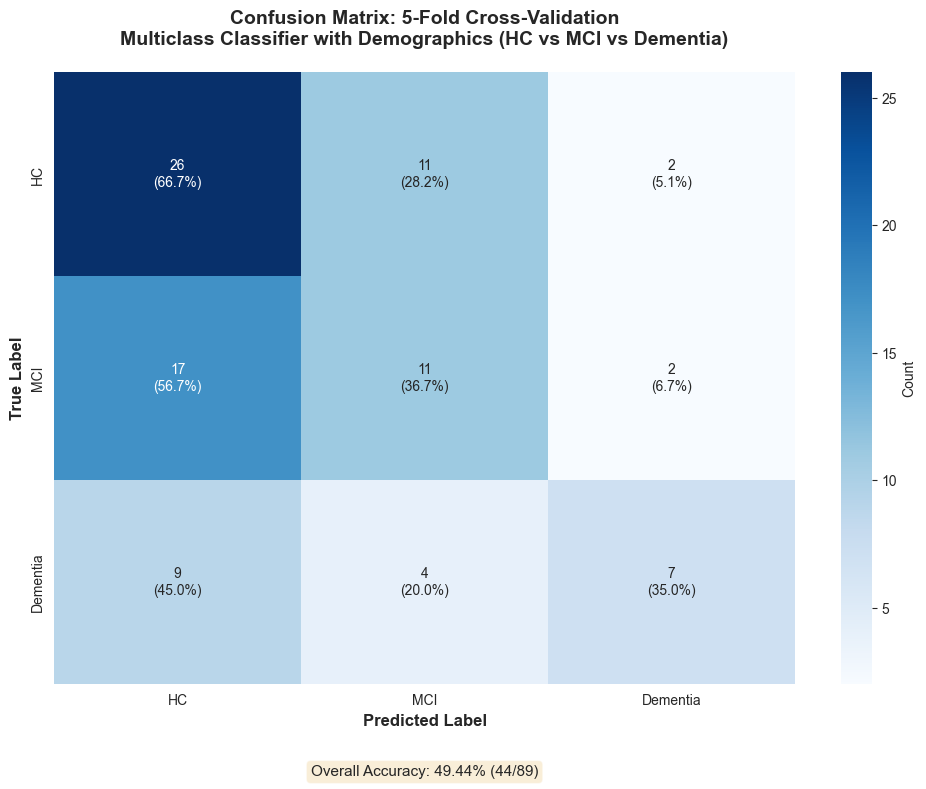

In [147]:
# Plot confusion matrix for multiclass classification with demographics
cm_multiclass_demo = confusion_matrix(all_y_true_multiclass_demo, all_y_pred_multiclass_demo)

fig, ax = plt.subplots(figsize=(10, 8))

# Calculate percentages of each row (true class)
# This ensures each row sums to exactly 100%
row_sums_demo = cm_multiclass_demo.sum(axis=1)
# Avoid division by zero (shouldn't happen, but safety check)
row_sums_demo = np.where(row_sums_demo == 0, 1, row_sums_demo)

# Calculate percentages and normalize to ensure each row sums to exactly 100%
cm_percent_demo = np.zeros_like(cm_multiclass_demo, dtype=float)
for i in range(len(cm_multiclass_demo)):
    if row_sums_demo[i] > 0:
        # Calculate percentages for this row
        cm_percent_demo[i, :] = cm_multiclass_demo[i, :].astype('float') / row_sums_demo[i] * 100
        # Ensure it sums to exactly 100% by normalizing
        row_total = cm_percent_demo[i, :].sum()
        if row_total > 0:
            cm_percent_demo[i, :] = cm_percent_demo[i, :] / row_total * 100

# Create annotation labels with both count and percentage
annot_labels_demo = []
class_names = ['HC', 'MCI', 'Dementia']
for i in range(len(cm_multiclass_demo)):
    row = []
    for j in range(len(cm_multiclass_demo)):
        count = cm_multiclass_demo[i, j]
        percent = cm_percent_demo[i, j]
        row.append(f'{count}\n({percent:.1f}%)')
    annot_labels_demo.append(row)

# Create heatmap
sns.heatmap(
    cm_multiclass_demo, 
    annot=annot_labels_demo, 
    fmt='', 
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={'label': 'Count'},
    ax=ax
)

ax.set_xlabel('Predicted Label', fontsize=12, fontweight='bold')
ax.set_ylabel('True Label', fontsize=12, fontweight='bold')
ax.set_title(
    'Confusion Matrix: 5-Fold Cross-Validation\nMulticlass Classifier with Demographics (HC vs MCI vs Dementia)',
    fontsize=14,
    fontweight='bold',
    pad=20
)

# Add accuracy text
total_demo = cm_multiclass_demo.sum()
correct_demo = np.trace(cm_multiclass_demo)
accuracy_demo = correct_demo / total_demo
ax.text(
    0.5, -0.15,
    f'Overall Accuracy: {accuracy_demo*100:.2f}% ({correct_demo}/{total_demo})',
    transform=ax.transAxes,
    ha='center',
    fontsize=11,
    bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5)
)

plt.tight_layout()
plt.show()


In [148]:
# Display confusion matrix as pandas DataFrame (with demographics)
cm_df_demo = pd.DataFrame(
    cm_multiclass_demo,
    index=['True: HC', 'True: MCI', 'True: Dementia'],
    columns=['Pred: HC', 'Pred: MCI', 'Pred: Dementia']
)

# Add row totals
cm_df_demo['Total'] = cm_df_demo.sum(axis=1)

# Calculate percentages for each row
cm_percent_df_demo = pd.DataFrame(
    cm_percent_demo,
    index=['True: HC', 'True: MCI', 'True: Dementia'],
    columns=['Pred: HC', 'Pred: MCI', 'Pred: Dementia']
)

print("\n" + "=" * 80)
print("CONFUSION MATRIX (Counts) - WITH DEMOGRAPHICS")
print("=" * 80)
display(cm_df_demo)

print("\n" + "=" * 80)
print("CONFUSION MATRIX (Percentages - each row sums to 100%) - WITH DEMOGRAPHICS")
print("=" * 80)
# Format percentages
cm_percent_df_formatted_demo = cm_percent_df_demo.map(lambda x: f'{x:.1f}%')
display(cm_percent_df_formatted_demo)
print("=" * 80 + "\n")



CONFUSION MATRIX (Counts) - WITH DEMOGRAPHICS


,Pred: HC,Pred: MCI,Pred: Dementia,Total
True: HC,26,11,2,39
True: MCI,17,11,2,30
True: Dementia,9,4,7,20



CONFUSION MATRIX (Percentages - each row sums to 100%) - WITH DEMOGRAPHICS


,Pred: HC,Pred: MCI,Pred: Dementia
True: HC,66.7%,28.2%,5.1%
True: MCI,56.7%,36.7%,6.7%
True: Dementia,45.0%,20.0%,35.0%


## Repeated Words Feature Analysis

Investigate the new repeated words feature: compute the number of repeated words per recording and analyze whether it makes a difference in classification performance.


In [149]:
# Compute repeated words statistics by diagnosis
# Reload the module to get the updated function
import importlib
import binary_classifier
importlib.reload(binary_classifier)
from binary_classifier import compute_repeated_words_metrics
from pathlib import Path

# Get all transcript files
transcript_paths = loader.discover_transcript_files()

# Compute repeated words for each transcript
repeated_words_data = []
for path in transcript_paths:
    recording_name = path.parent.name
    task = loader.infer_task_from_filename(path.name)
    
    if task not in ['PFT', 'SFT']:
        continue
    
    repeated_metrics = compute_repeated_words_metrics(path)
    
    repeated_words_data.append({
        'recording': recording_name,
        'task': task,
        'repeated_words_count': repeated_metrics['repeated_words_count'],
        'repeated_words_std': repeated_metrics['repeated_words_std'],
        'transcript_path': str(path)
    })

repeated_words_df = pd.DataFrame(repeated_words_data)

# Merge with metadata to get diagnosis
metadata_for_merge = metadata.copy()
if 'anyon_IDs' in metadata_for_merge.columns:
    metadata_for_merge = metadata_for_merge.rename(columns={'anyon_IDs': 'recording'})

repeated_words_with_diag = repeated_words_df.merge(
    metadata_for_merge[['recording', 'diagnosis']],
    on='recording',
    how='left'
)

# Filter to only records with diagnosis
repeated_words_with_diag = repeated_words_with_diag.dropna(subset=['diagnosis'])

# Convert diagnosis to categorical
repeated_words_with_diag['diagnosis'] = pd.Categorical(
    repeated_words_with_diag['diagnosis'],
    categories=['DEMENTIA', 'HC', 'MCI'],
    ordered=True
)

print("=" * 80)
print("REPEATED WORDS STATISTICS BY DIAGNOSIS")
print("=" * 80)

# Summary statistics by diagnosis and task
for task in ['PFT', 'SFT']:
    task_data = repeated_words_with_diag[repeated_words_with_diag['task'] == task]
    print(f"\n{task} Task:")
    print("-" * 80)
    
    summary = task_data.groupby('diagnosis')['repeated_words_count'].agg([
        'count', 'mean', 'std', 'min', 'max', 'median'
    ]).round(2)
    
    print(summary)
    
    # Statistical comparison
    print(f"\n{task} - Statistical Summary:")
    for diag in ['DEMENTIA', 'HC', 'MCI']:
        diag_data = task_data[task_data['diagnosis'] == diag]['repeated_words_count']
        if len(diag_data) > 0:
            print(f"  {diag:10s}: Mean = {diag_data.mean():.2f}, Median = {diag_data.median():.2f}, "
                  f"Std = {diag_data.std():.2f}, N = {len(diag_data)}")

print("\n" + "=" * 80)


REPEATED WORDS STATISTICS BY DIAGNOSIS

PFT Task:
--------------------------------------------------------------------------------
           count  mean   std  min  max  median
diagnosis                                     
DEMENTIA      20  0.35  0.75    0    3     0.0
HC            39  0.72  1.15    0    5     0.0
MCI           31  0.90  0.87    0    3     1.0

PFT - Statistical Summary:
  DEMENTIA  : Mean = 0.35, Median = 0.00, Std = 0.75, N = 20
  HC        : Mean = 0.72, Median = 0.00, Std = 1.15, N = 39
  MCI       : Mean = 0.90, Median = 1.00, Std = 0.87, N = 31

SFT Task:
--------------------------------------------------------------------------------
           count  mean   std  min  max  median
diagnosis                                     
DEMENTIA      20  0.60  0.68    0    2     0.5
HC            39  0.62  1.25    0    6     0.0
MCI           30  0.60  0.81    0    2     0.0

SFT - Statistical Summary:
  DEMENTIA  : Mean = 0.60, Median = 0.50, Std = 0.68, N = 20
  HC   

/var/folders/ll/3tyvzctx1372nslqytmh85100000gn/T/ipykernel_54128/1633908341.py:64: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  summary = task_data.groupby('diagnosis')['repeated_words_count'].agg([
/var/folders/ll/3tyvzctx1372nslqytmh85100000gn/T/ipykernel_54128/1633908341.py:64: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  summary = task_data.groupby('diagnosis')['repeated_words_count'].agg([


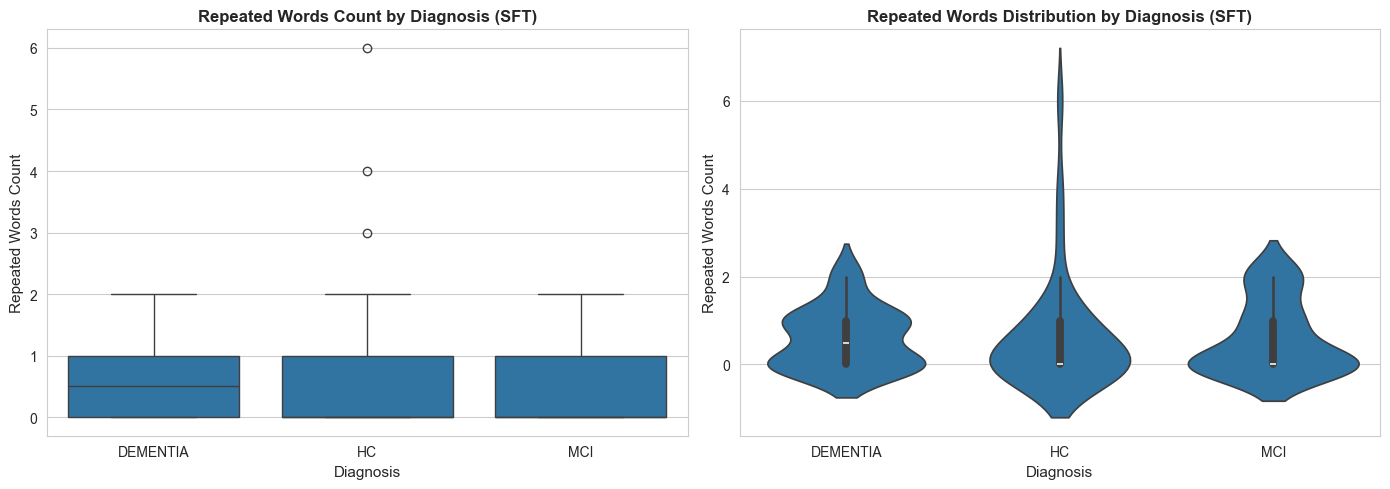

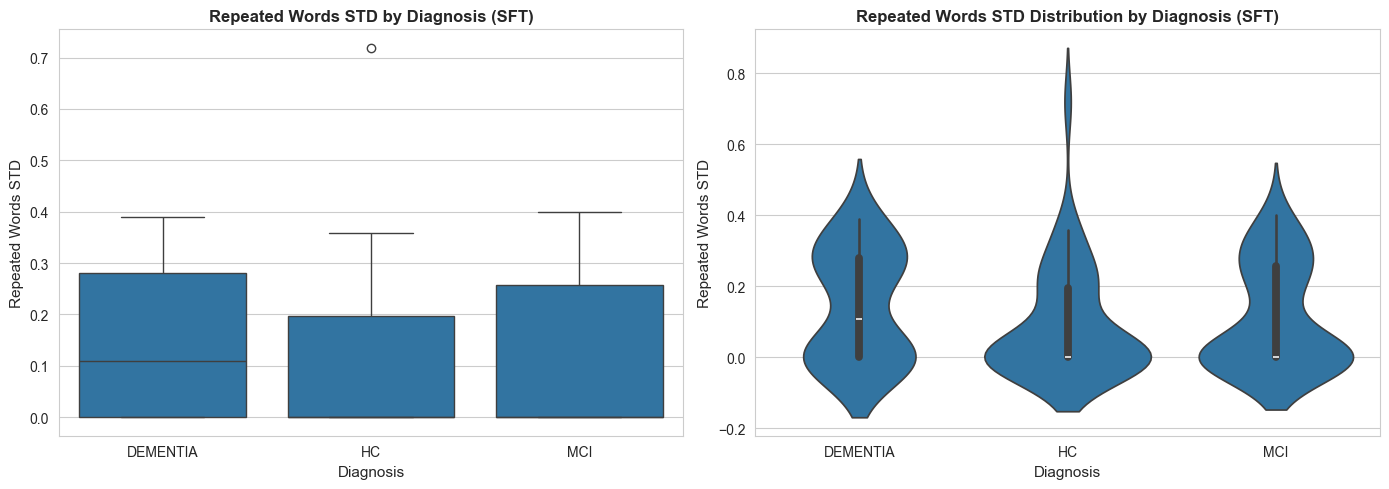


DESCRIPTIVE STATISTICS: Repeated Words Count (SFT)

diagnosis Statistics:
           count      mean       std  25%  50%  75%
diagnosis                                          
DEMENTIA    20.0  0.600000  0.680557  0.0  0.5  1.0
HC          39.0  0.615385  1.248481  0.0  0.0  1.0
MCI         30.0  0.600000  0.813676  0.0  0.0  1.0


DESCRIPTIVE STATISTICS: Repeated Words STD (SFT)

diagnosis Statistics:
           count      mean       std  25%       50%       75%
diagnosis                                                    
DEMENTIA    20.0  0.145336  0.153643  0.0  0.109109  0.280181
HC          39.0  0.094469  0.157960  0.0  0.000000  0.196116
MCI         30.0  0.111575  0.145147  0.0  0.000000  0.257800



In [150]:
# Visualize repeated words distribution by diagnosis
import matplotlib.pyplot as plt
import seaborn as sns

# Filter to SFT only for visualization (since that's what we use for classification)
sft_repeated = repeated_words_with_diag[repeated_words_with_diag['task'] == 'SFT'].copy()

# Plot 1: Repeated Words Count
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Box plot
ax1 = axes[0]
sns.boxplot(data=sft_repeated, x='diagnosis', y='repeated_words_count', ax=ax1)
ax1.set_title('Repeated Words Count by Diagnosis (SFT)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Diagnosis', fontsize=11)
ax1.set_ylabel('Repeated Words Count', fontsize=11)

# Violin plot
ax2 = axes[1]
sns.violinplot(data=sft_repeated, x='diagnosis', y='repeated_words_count', ax=ax2)
ax2.set_title('Repeated Words Distribution by Diagnosis (SFT)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Diagnosis', fontsize=11)
ax2.set_ylabel('Repeated Words Count', fontsize=11)

plt.tight_layout()
plt.show()

# Plot 2: Repeated Words STD
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Box plot
ax1 = axes[0]
sns.boxplot(data=sft_repeated, x='diagnosis', y='repeated_words_std', ax=ax1)
ax1.set_title('Repeated Words STD by Diagnosis (SFT)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Diagnosis', fontsize=11)
ax1.set_ylabel('Repeated Words STD', fontsize=11)

# Violin plot
ax2 = axes[1]
sns.violinplot(data=sft_repeated, x='diagnosis', y='repeated_words_std', ax=ax2)
ax2.set_title('Repeated Words STD Distribution by Diagnosis (SFT)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Diagnosis', fontsize=11)
ax2.set_ylabel('Repeated Words STD', fontsize=11)

plt.tight_layout()
plt.show()

# Print descriptive statistics
print("\n" + "=" * 80)
print("DESCRIPTIVE STATISTICS: Repeated Words Count (SFT)")
print("=" * 80)
print_descriptive_stats(sft_repeated, 'diagnosis', value_col='repeated_words_count')
print("=" * 80 + "\n")

print("\n" + "=" * 80)
print("DESCRIPTIVE STATISTICS: Repeated Words STD (SFT)")
print("=" * 80)
print_descriptive_stats(sft_repeated, 'diagnosis', value_col='repeated_words_std')
print("=" * 80 + "\n")


In [151]:
# Compare binary classifier performance WITH and WITHOUT repeated words feature
from binary_classifier import build_feature_dataset, get_classifier, evaluate_with_cv
from sklearn.model_selection import StratifiedKFold

print("=" * 80)
print("BINARY CLASSIFIER COMPARISON: With vs Without Repeated Words Feature")
print("=" * 80)

# Build feature dataset (includes repeated words now)
features_df_with_repeated = build_feature_dataset(
    data_dir=loader.data_dir,
    metadata_path=loader.metadata_path,
    include_pft=False  # Use SFT only
)

print(f"\nLoaded {len(features_df_with_repeated)} recordings")
print(f"  - Dementia: {sum(features_df_with_repeated['label'] == 1)}")
print(f"  - Healthy (HC): {sum(features_df_with_repeated['label'] == 0)}")

# Prepare features WITH repeated words
feature_cols_with = [col for col in features_df_with_repeated.columns 
                     if col.startswith('sft_')]
X_with = features_df_with_repeated[feature_cols_with].fillna(0)
y_with = features_df_with_repeated['label']

# Prepare features WITHOUT repeated words (exclude both repeated_words_count and repeated_words_std)
feature_cols_without = [col for col in feature_cols_with 
                       if 'repeated_words_count' not in col and 'repeated_words_std' not in col]
X_without = features_df_with_repeated[feature_cols_without].fillna(0)
y_without = features_df_with_repeated['label']

print(f"\nFeatures WITH repeated words: {len(feature_cols_with)}")
print(f"Features WITHOUT repeated words: {len(feature_cols_without)}")
print(f"\nRepeated words features included:")
print(f"  - sft_repeated_words_count: {'sft_repeated_words_count' in feature_cols_with}")
print(f"  - sft_repeated_words_std: {'sft_repeated_words_std' in feature_cols_with}")

# Get classifier
classifier = get_classifier('logistic')

# Evaluate WITH repeated words
print("\n" + "-" * 80)
print("Evaluating WITH repeated words feature...")
print("-" * 80)
cv_results_with = evaluate_with_cv(X_with, y_with, classifier, k_folds=5)

# Evaluate WITHOUT repeated words
print("\n" + "-" * 80)
print("Evaluating WITHOUT repeated words feature...")
print("-" * 80)
cv_results_without = evaluate_with_cv(X_without, y_without, classifier, k_folds=5)

# Compare results
print("\n" + "=" * 80)
print("COMPARISON: With vs Without Repeated Words Feature")
print("=" * 80)

comparison_metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
comparison_data = []

for metric in comparison_metrics:
    with_mean = cv_results_with.get(f'{metric}_mean', 0)
    with_std = cv_results_with.get(f'{metric}_std', 0)
    without_mean = cv_results_without.get(f'{metric}_mean', 0)
    without_std = cv_results_without.get(f'{metric}_std', 0)
    
    improvement = with_mean - without_mean
    improvement_pct = (improvement / without_mean * 100) if without_mean > 0 else 0
    
    comparison_data.append({
        'Metric': metric.capitalize(),
        'Without Repeated Words': f'{without_mean:.4f} ± {without_std:.4f}',
        'With Repeated Words': f'{with_mean:.4f} ± {with_std:.4f}',
        'Improvement': f'{improvement:+.4f} ({improvement_pct:+.2f}%)'
    })

comparison_df = pd.DataFrame(comparison_data)
display(comparison_df)
print("=" * 80 + "\n")


BINARY CLASSIFIER COMPARISON: With vs Without Repeated Words Feature

Loaded 59 recordings
  - Dementia: 20
  - Healthy (HC): 39

Features WITH repeated words: 12
Features WITHOUT repeated words: 10

Repeated words features included:
  - sft_repeated_words_count: True
  - sft_repeated_words_std: True

--------------------------------------------------------------------------------
Evaluating WITH repeated words feature...
--------------------------------------------------------------------------------

--------------------------------------------------------------------------------
Evaluating WITHOUT repeated words feature...
--------------------------------------------------------------------------------

COMPARISON: With vs Without Repeated Words Feature


,Metric,Without Repeated Words,With Repeated Words,Improvement
0,Accuracy,0.7955 ± 0.0706,0.7788 ± 0.0695,-0.0167 (-2.10%)
1,Precision,0.7367 ± 0.1400,0.7067 ± 0.1497,-0.0300 (-4.07%)
2,Recall,0.6500 ± 0.1225,0.6500 ± 0.1225,+0.0000 (+0.00%)
3,F1,0.6833 ± 0.1095,0.6667 ± 0.1043,-0.0167 (-2.44%)
4,Roc_auc,0.8179 ± 0.0762,0.7982 ± 0.0941,-0.0196 (-2.40%)


In [152]:
# Show feature importance/coefficients for repeated words feature
print("=" * 80)
print("FEATURE IMPORTANCE: Repeated Words Feature")
print("=" * 80)

# Train final model on all data WITH repeated words
classifier.fit(X_with, y_with)

# Get coefficients
coefficients = classifier.named_steps['classifier'].coef_[0]
feature_importance = pd.DataFrame({
    'feature': feature_cols_with,
    'coefficient': coefficients,
}).sort_values('coefficient', key=abs, ascending=False)

# Check if repeated words features are in the top features
repeated_words_count_row = feature_importance[feature_importance['feature'] == 'sft_repeated_words_count']
repeated_words_std_row = feature_importance[feature_importance['feature'] == 'sft_repeated_words_std']

print("\nRepeated Words Features:")
print("-" * 80)

# Repeated Words Count
if len(repeated_words_count_row) > 0:
    row = repeated_words_count_row.iloc[0]
    print(f"\n  Feature: {row['feature']}")
    print(f"  Coefficient: {row['coefficient']:.6f}")
    print(f"  Absolute Coefficient: {abs(row['coefficient']):.6f}")
    
    # Rank among all features
    rank = (feature_importance['coefficient'].abs().rank(ascending=False, method='min')
            [feature_importance['feature'] == 'sft_repeated_words_count']).iloc[0]
    print(f"  Rank (by absolute coefficient): {int(rank)} out of {len(feature_importance)}")
    
    # Interpretation
    if row['coefficient'] > 0:
        print(f"  Interpretation: Higher repeated words count is associated with Dementia")
    else:
        print(f"  Interpretation: Higher repeated words count is associated with Healthy controls")
else:
    print("\n  Repeated words count feature not found in feature list")

# Repeated Words STD
if len(repeated_words_std_row) > 0:
    row = repeated_words_std_row.iloc[0]
    print(f"\n  Feature: {row['feature']}")
    print(f"  Coefficient: {row['coefficient']:.6f}")
    print(f"  Absolute Coefficient: {abs(row['coefficient']):.6f}")
    
    # Rank among all features
    rank = (feature_importance['coefficient'].abs().rank(ascending=False, method='min')
            [feature_importance['feature'] == 'sft_repeated_words_std']).iloc[0]
    print(f"  Rank (by absolute coefficient): {int(rank)} out of {len(feature_importance)}")
    
    # Interpretation
    if row['coefficient'] > 0:
        print(f"  Interpretation: Higher repeated words STD is associated with Dementia")
    else:
        print(f"  Interpretation: Higher repeated words STD is associated with Healthy controls")
else:
    print("\n  Repeated words STD feature not found in feature list")

print("\nTop 10 Features (by absolute coefficient):")
print("-" * 80)
display(feature_importance.head(10))

print("\n" + "=" * 80)


FEATURE IMPORTANCE: Repeated Words Feature

Repeated Words Features:
--------------------------------------------------------------------------------

  Feature: sft_repeated_words_count
  Coefficient: -0.471382
  Absolute Coefficient: 0.471382
  Rank (by absolute coefficient): 6 out of 12
  Interpretation: Higher repeated words count is associated with Healthy controls

  Feature: sft_repeated_words_std
  Coefficient: 0.304258
  Absolute Coefficient: 0.304258
  Rank (by absolute coefficient): 9 out of 12
  Interpretation: Higher repeated words STD is associated with Dementia

Top 10 Features (by absolute coefficient):
--------------------------------------------------------------------------------


,feature,coefficient
2,sft_pause_median,0.980364
8,sft_pause_q2,0.980364
6,sft_pause_total,-0.698662
7,sft_pause_q1,0.495599
0,sft_pause_count,-0.479148
10,sft_repeated_words_count,-0.471382
3,sft_pause_min,-0.457663
4,sft_pause_max,0.367831
11,sft_repeated_words_std,0.304258
5,sft_pause_std,0.291232


In [153]:
# Statistical test: Compare repeated words between Dementia and HC
from scipy import stats

print("=" * 80)
print("STATISTICAL TEST: Repeated Words Count (Dementia vs HC)")
print("=" * 80)

# Filter to SFT and binary comparison (Dementia vs HC)
sft_binary = sft_repeated[sft_repeated['diagnosis'].isin(['DEMENTIA', 'HC'])].copy()

dementia_repeated = sft_binary[sft_binary['diagnosis'] == 'DEMENTIA']['repeated_words_count']
hc_repeated = sft_binary[sft_binary['diagnosis'] == 'HC']['repeated_words_count']

# Perform t-test
t_stat, p_value = stats.ttest_ind(dementia_repeated, hc_repeated)

print(f"\nDementia (N={len(dementia_repeated)}):")
print(f"  Mean: {dementia_repeated.mean():.2f}")
print(f"  Std:  {dementia_repeated.std():.2f}")
print(f"  Median: {dementia_repeated.median():.2f}")

print(f"\nHealthy Controls (N={len(hc_repeated)}):")
print(f"  Mean: {hc_repeated.mean():.2f}")
print(f"  Std:  {hc_repeated.std():.2f}")
print(f"  Median: {hc_repeated.median():.2f}")

print(f"\nTwo-tailed t-test:")
print(f"  t-statistic: {t_stat:.4f}")
print(f"  p-value: {p_value:.4f}")
print(f"  Significant (p < 0.05): {'Yes *' if p_value < 0.05 else 'No'}")

print("\n" + "=" * 80)

# Statistical test: Compare repeated words STD between Dementia and HC
print("\n" + "=" * 80)
print("STATISTICAL TEST: Repeated Words STD (Dementia vs HC)")
print("=" * 80)

dementia_repeated_std = sft_binary[sft_binary['diagnosis'] == 'DEMENTIA']['repeated_words_std']
hc_repeated_std = sft_binary[sft_binary['diagnosis'] == 'HC']['repeated_words_std']

# Perform t-test
t_stat_std, p_value_std = stats.ttest_ind(dementia_repeated_std, hc_repeated_std)

print(f"\nDementia (N={len(dementia_repeated_std)}):")
print(f"  Mean: {dementia_repeated_std.mean():.2f}")
print(f"  Std:  {dementia_repeated_std.std():.2f}")
print(f"  Median: {dementia_repeated_std.median():.2f}")

print(f"\nHealthy Controls (N={len(hc_repeated_std)}):")
print(f"  Mean: {hc_repeated_std.mean():.2f}")
print(f"  Std:  {hc_repeated_std.std():.2f}")
print(f"  Median: {hc_repeated_std.median():.2f}")

print(f"\nTwo-tailed t-test:")
print(f"  t-statistic: {t_stat_std:.4f}")
print(f"  p-value: {p_value_std:.4f}")
print(f"  Significant (p < 0.05): {'Yes *' if p_value_std < 0.05 else 'No'}")

print("\n" + "=" * 80)


STATISTICAL TEST: Repeated Words Count (Dementia vs HC)

Dementia (N=20):
  Mean: 0.60
  Std:  0.68
  Median: 0.50

Healthy Controls (N=39):
  Mean: 0.62
  Std:  1.25
  Median: 0.00

Two-tailed t-test:
  t-statistic: -0.0512
  p-value: 0.9593
  Significant (p < 0.05): No


STATISTICAL TEST: Repeated Words STD (Dementia vs HC)

Dementia (N=20):
  Mean: 0.15
  Std:  0.15
  Median: 0.11

Healthy Controls (N=39):
  Mean: 0.09
  Std:  0.16
  Median: 0.00

Two-tailed t-test:
  t-statistic: 1.1815
  p-value: 0.2423
  Significant (p < 0.05): No

